#EDA OF MULTICLASS CYBERBULLYING


In [8]:

from pathlib import Path

# Dataset location:
# Update this path to the location of the English Cyberbullying dataset.
# The dataset is not included in this GitHub repository.
PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "multiclass-cyberbullying-detection"
)

# Dataset directories
DATA_DIR = Path(
    "/content/drive/MyDrive/Cyberbullying_Project/"
    "Datasets/English_dataset"
)

MULTICLASS_DATA_DIR = (
    DATA_DIR / "multiclass_splits_80_20_MASTER_ALLMODELS"
)

DATA_PATH = DATA_DIR / "cyberbullying_tweets.csv"


In [9]:
# Load the original English cyberbullying dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["cyberbullying_type"].value_counts())

print("\nClass proportion:")
print(df["cyberbullying_type"].value_counts(normalize=True))


Dataset loaded successfully!
Shape: (47692, 2)

Columns:
['tweet_text', 'cyberbullying_type']

Class distribution:
cyberbullying_type
religion               7998
age                    7992
gender                 7973
ethnicity              7961
not_cyberbullying      7945
other_cyberbullying    7823
Name: count, dtype: int64

Class proportion:
cyberbullying_type
religion               0.167701
age                    0.167575
gender                 0.167177
ethnicity              0.166925
not_cyberbullying      0.166590
other_cyberbullying    0.164032
Name: proportion, dtype: float64


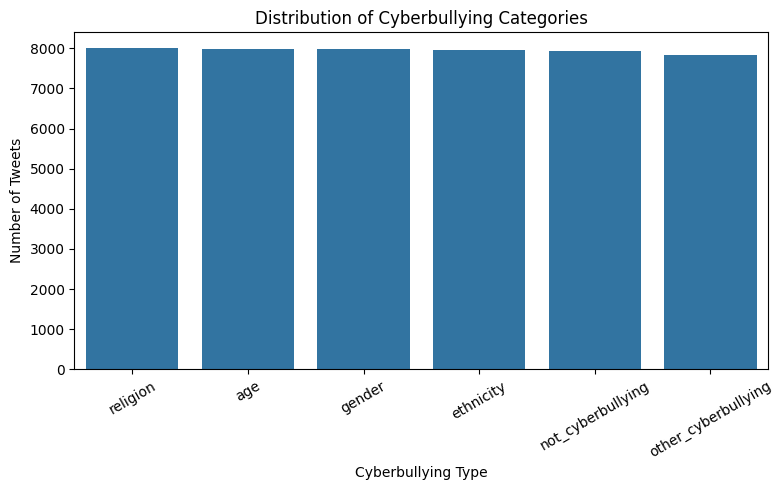

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="cyberbullying_type",
    order=df["cyberbullying_type"].value_counts().index
)

plt.title("Distribution of Cyberbullying Categories")
plt.xlabel("Cyberbullying Type")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=300)
plt.show()
plt.close()


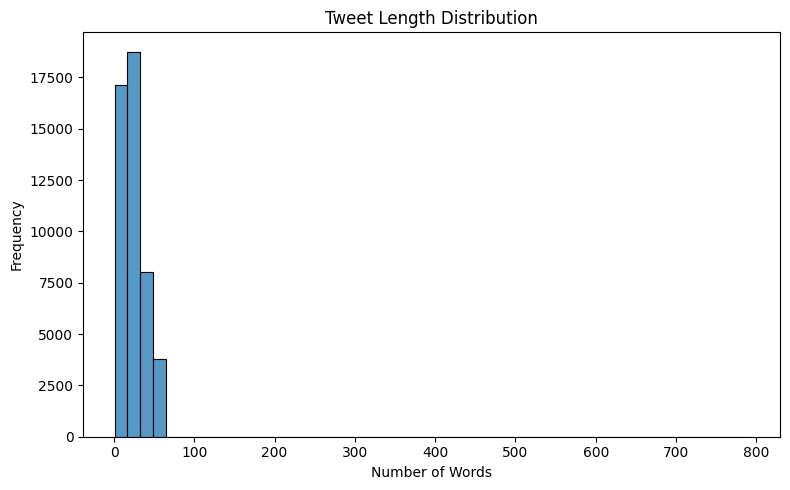

In [9]:

df["text_length"] = df["tweet_text"].apply(
    lambda x: len(str(x).split())
)

plt.figure(figsize=(8, 5))
sns.histplot(df["text_length"], bins=50)

plt.title("Tweet Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tweet_length_distribution.png", dpi=300)
plt.show()
plt.close()


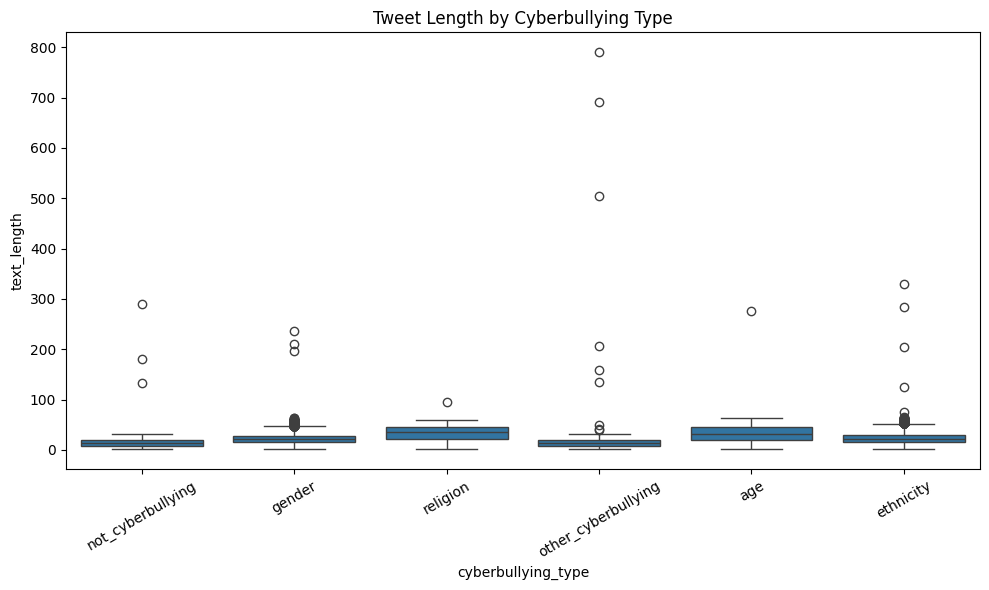

In [10]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="cyberbullying_type",
    y="text_length"
)

plt.xticks(rotation=30)
plt.title("Tweet Length by Cyberbullying Type")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tweet_length_by_class.png", dpi=300)
plt.show()
plt.close()


In [11]:

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20
)

X = vectorizer.fit_transform(df["tweet_text"])

words = vectorizer.get_feature_names_out()
counts = X.sum(axis=0).A1

word_freq = pd.DataFrame({
    "word": words,
    "count": counts
}).sort_values("count", ascending=False)

print(word_freq)


       word  count
19   school   8877
14     like   5914
6      fuck   5884
5      dumb   5392
10     high   5261
16   people   4905
2   bullied   4702
13     just   4618
17     rape   4510
15   nigger   4470
18       rt   4350
7       gay   4237
4       don   3877
3     bully   3758
12    jokes   3526
11     http   3309
0       amp   2972
9     girls   2837
1       ass   2822
8      girl   2778


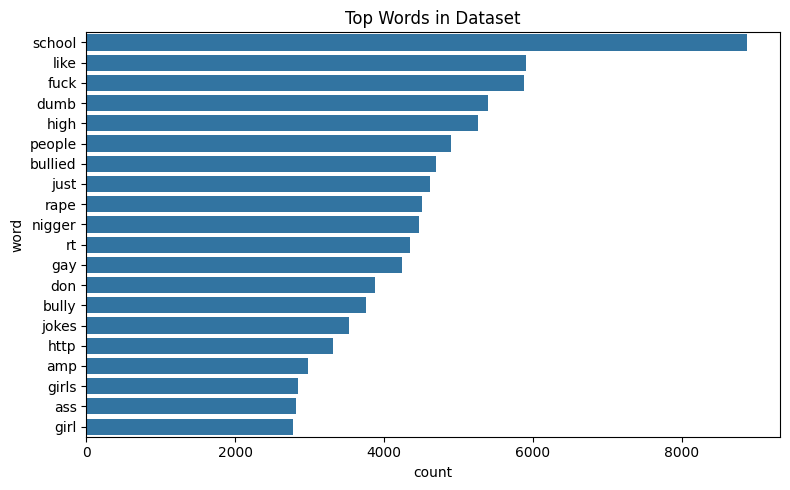

In [12]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=word_freq,
    x="count",
    y="word"
)

plt.title("Top Words in Dataset")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_words.png", dpi=300)
plt.show()
plt.close()


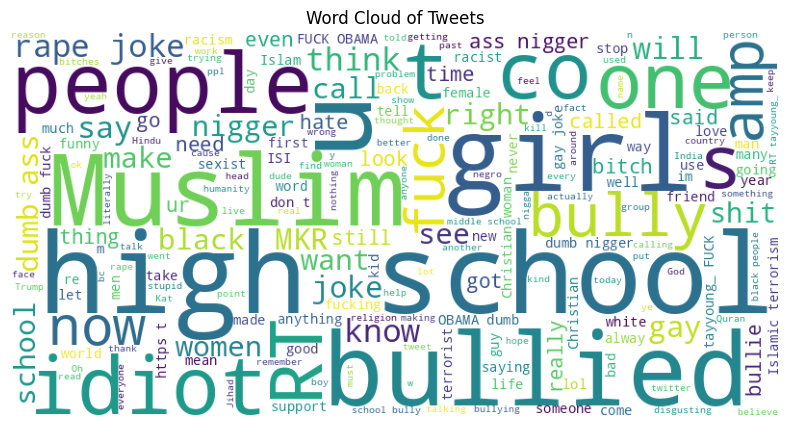

In [13]:

from wordcloud import WordCloud

text = " ".join(df["tweet_text"].astype(str))

wc = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc)
plt.axis("off")

plt.title("Word Cloud of Tweets")

plt.savefig(
    FIGURES_DIR / "wordcloud.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


#Data preparation for model training


In [6]:

import pandas as pd
import json

# Load existing prepared datasets
train_df_check = pd.read_csv(
    MULTICLASS_DATA_DIR / "train_80_MASTER_ALLMODELS.csv"
)

val_df_check = pd.read_csv(
    MULTICLASS_DATA_DIR / "val_from_train_MASTER_ALLMODELS.csv"
)

test_df_check = pd.read_csv(
    MULTICLASS_DATA_DIR / "test_20_MASTER_ALLMODELS.csv"
)

# Load label mapping
with open(MULTICLASS_DATA_DIR / "label2id.json", "r") as f:
    label2id_check = json.load(f)

with open(MULTICLASS_DATA_DIR / "id2label.json", "r") as f:
    id2label_check = json.load(f)

print("DATASET SIZES")
print("-------------------------")
print("Training:", train_df_check.shape)
print("Validation:", val_df_check.shape)
print("Testing:", test_df_check.shape)

print("\nCOLUMNS")
print("-------------------------")
print(train_df_check.columns.tolist())

print("\nLABEL MAPPING")
print("-------------------------")
print(label2id_check)

print("\nCLASS COUNTS IN EACH SPLIT")
print("-------------------------")

for name, data in [
    ("Training", train_df_check),
    ("Validation", val_df_check),
    ("Testing", test_df_check)
]:
    print(f"\n{name}:")
    print(data["cyberbullying_type"].value_counts().sort_index())

print("\nLABEL CONSISTENCY")
print("-------------------------")

for name, data in [
    ("Training", train_df_check),
    ("Validation", val_df_check),
    ("Testing", test_df_check)
]:
    valid_labels = data["label"].isin(label2id_check.values()).all()
    print(f"{name} labels valid:", valid_labels)

print("\nTEXT COLUMNS")
print("-------------------------")

for col in ["text_ml", "text_trf"]:
    print(
        f"{col} exists:",
        col in train_df_check.columns
    )


DATASET SIZES
-------------------------
Training: (32430, 5)
Validation: (5723, 5)
Testing: (9539, 5)

COLUMNS
-------------------------
['tweet_text', 'cyberbullying_type', 'label', 'text_ml', 'text_trf']

LABEL MAPPING
-------------------------
{'age': 0, 'ethnicity': 1, 'gender': 2, 'not_cyberbullying': 3, 'other_cyberbullying': 4, 'religion': 5}

CLASS COUNTS IN EACH SPLIT
-------------------------

Training:
cyberbullying_type
age                    5435
ethnicity              5414
gender                 5421
not_cyberbullying      5403
other_cyberbullying    5319
religion               5438
Name: count, dtype: int64

Validation:
cyberbullying_type
age                    959
ethnicity              955
gender                 957
not_cyberbullying      953
other_cyberbullying    939
religion               960
Name: count, dtype: int64

Testing:
cyberbullying_type
age                    1598
ethnicity              1592
gender                 1595
not_cyberbullying      1589
other_cyb

In [18]:
MODEL_DIRS = {
    "ML": RESULTS_DIR / "ML_Multiclass_80_20",
    "CNN": RESULTS_DIR / "CNN_Multiclass_80_20",
    "CNN_GLOVE": RESULTS_DIR / "CNN_GloVe_Multiclass_80_20",
    "BILSTM": RESULTS_DIR / "BiLSTM_Multiclass_80_20",
    "BILSTM_GLOVE": RESULTS_DIR / "BiLSTM_GloVe_Multiclass_80_20",
    "BERT": RESULTS_DIR / "BERT_Multiclass_80_20",
    "ROBERTA": RESULTS_DIR / "RoBERTa_Multiclass_80_20",
    "ENSEMBLE_BERT": RESULTS_DIR / "Soft_Voting_Ensemble_BERT_CNN_GloVe",
    "ENSEMBLE_ROBERTA": RESULTS_DIR / "Soft_Voting_Ensemble_RoBERTa_CNN_GloVe"
}

# Create all directories
for directory in MODEL_DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

print("Model output directories created:\n")

for name, directory in MODEL_DIRS.items():
    print(f"{name}: {directory}")

Model output directories created:

ML: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/ML_Multiclass_80_20
CNN: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_Multiclass_80_20
CNN_GLOVE: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20
BILSTM: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_Multiclass_80_20
BILSTM_GLOVE: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_GloVe_Multiclass_80_20
BERT: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20
ROBERTA: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20
ENSEMBLE_BERT: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_BERT_CNN_GloVe
ENSEMBLE_ROBERTA: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe


#ML Model Training

In [19]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)


# Paths

DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
TRAIN_PATH = os.path.join(DATA_DIR, "train_80_MASTER_ALLMODELS.csv")
VAL_PATH   = os.path.join(DATA_DIR, "val_from_train_MASTER_ALLMODELS.csv")
TEST_PATH  = os.path.join(DATA_DIR, "test_20_MASTER_ALLMODELS.csv")
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

RESULTS_DIR = str(MODEL_DIRS["ML"])
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load data
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

TEXT_COL = "text_ml" if "text_ml" in train_df.columns else "tweet_text"

X_train = train_df[TEXT_COL].fillna("").astype(str).values
y_train = train_df["label"].astype(int).values

X_val   = val_df[TEXT_COL].fillna("").astype(str).values
y_val   = val_df["label"].astype(int).values

X_test  = test_df[TEXT_COL].fillna("").astype(str).values
y_test  = test_df["label"].astype(int).values

# Label names
if os.path.exists(ID2LABEL_PATH):
    id2label = json.load(open(ID2LABEL_PATH))
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    # fallback: build names from dataset (less stable order)
    label_names = sorted(train_df["cyberbullying_type"].unique())

K = len(label_names)
print("Classes (K):", K)
print("Text column:", TEXT_COL)
print("Train/Val/Test:", len(X_train), len(X_val), len(X_test))

# TF-IDF

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
Xtr = vectorizer.fit_transform(X_train)
Xva = vectorizer.transform(X_val)
Xte = vectorizer.transform(X_test)

# confusion matrix
def save_confusion_matrix(y_true, y_pred, title, out_path):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=label_names)
    fig, ax = plt.subplots(figsize=(9,7))
    disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.close()
    print("Saved:", out_path)

# ROC OVR
def save_roc_ovr(y_true, y_prob, title, out_path):
    # y_prob shape: [N, K]
    y_true_bin = label_binarize(y_true, classes=list(range(K)))
    plt.figure(figsize=(8,6))
    for c in range(K):
        fpr, tpr, _ = roc_curve(y_true_bin[:, c], y_prob[:, c])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc:.2f})")
    plt.plot([0,1],[0,1], linestyle="--", lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.close()
    print("Saved:", out_path)

# 1) Logistic Regression (Multinomial)
lr = LogisticRegression(
    max_iter=3000,
    solver="lbfgs",
    multi_class="multinomial"
)
lr.fit(Xtr, y_train)

lr_pred = lr.predict(Xte)
lr_prob = lr.predict_proba(Xte)

print("TF-IDF + Logistic Regression (TEST)")
print(classification_report(y_test, lr_pred, target_names=label_names, digits=4))

save_confusion_matrix(
    y_test, lr_pred,
    "TF-IDF + Logistic Regression Confusion Matrix (TEST)",
    os.path.join(RESULTS_DIR, "CM_LR_TEST.png")
)
save_roc_ovr(
    y_test, lr_prob,
    "TF-IDF + Logistic Regression ROC (OVR, TEST)",
    os.path.join(RESULTS_DIR, "ROC_LR_OVR_TEST.png")
)

# 2) Linear SVM (+ calibration for ROC probs)
svm = LinearSVC()
svm.fit(Xtr, y_train)

# Calibrate using validation set to get probabilities
cal = CalibratedClassifierCV(svm, method="sigmoid", cv="prefit")
cal.fit(Xva, y_val)

svm_pred = cal.predict(Xte)
svm_prob = cal.predict_proba(Xte)

print("\n==============================")
print("TF-IDF + Linear SVM (Calibrated) (TEST)")
print("==============================")
print(classification_report(y_test, svm_pred, target_names=label_names, digits=4))

save_confusion_matrix(
    y_test, svm_pred,
    "TF-IDF + Linear SVM (Calibrated) Confusion Matrix (TEST)",
    os.path.join(RESULTS_DIR, "CM_SVM_TEST.png")
)
save_roc_ovr(
    y_test, svm_prob,
    "TF-IDF + Linear SVM (Calibrated) ROC (OVR, TEST)",
    os.path.join(RESULTS_DIR, "ROC_SVM_OVR_TEST.png")
)

print("\nAll ML multiclass results saved in:", RESULTS_DIR)

Classes (K): 6
Text column: text_ml
Train/Val/Test: 32430 5723 9539


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



TF-IDF + Logistic Regression (TEST)
                     precision    recall  f1-score   support

                age     0.9661    0.9812    0.9736      1598
          ethnicity     0.9765    0.9673    0.9719      1592
             gender     0.9055    0.8295    0.8658      1595
  not_cyberbullying     0.6058    0.5242    0.5621      1589
other_cyberbullying     0.5874    0.7169    0.6458      1565
           religion     0.9479    0.9437    0.9458      1600

           accuracy                         0.8278      9539
          macro avg     0.8316    0.8272    0.8275      9539
       weighted avg     0.8325    0.8278    0.8283      9539

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/ML_Multiclass_80_20/CM_LR_TEST.png
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/ML_Multiclass_80_20/ROC_LR_OVR_TEST.png


/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(



TF-IDF + Linear SVM (Calibrated) (TEST)
                     precision    recall  f1-score   support

                age     0.9597    0.9825    0.9709      1598
          ethnicity     0.9742    0.9730    0.9736      1592
             gender     0.8916    0.8401    0.8651      1595
  not_cyberbullying     0.5840    0.5098    0.5444      1589
other_cyberbullying     0.5772    0.6760    0.6227      1565
           religion     0.9553    0.9494    0.9524      1600

           accuracy                         0.8225      9539
          macro avg     0.8237    0.8218    0.8215      9539
       weighted avg     0.8246    0.8225    0.8224      9539

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/ML_Multiclass_80_20/CM_SVM_TEST.png
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/ML_Multiclass_80_20/ROC_SVM_OVR_TEST.png

All ML multiclass results saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/ML_Multiclass_80_20


In [20]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import os

# Binarize true labels for multiclass ROC-AUC (OvR)
y_test_bin = label_binarize(y_test, classes=list(range(K)))

def summarize_multiclass(y_true, y_pred, y_prob, name):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (Macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC (Macro OvR)": roc_auc_score(y_test_bin, y_prob, average="macro", multi_class="ovr"),
        "Precision (Weighted)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall (Weighted)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 (Weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

rows = []
rows.append(summarize_multiclass(y_test, lr_pred, lr_prob, "TF-IDF + Logistic Regression"))
rows.append(summarize_multiclass(y_test, svm_pred, svm_prob, "TF-IDF + Linear SVM (Calibrated)"))

results_table = pd.DataFrame(rows)

# Pretty print (rounded)
print(results_table.round(4))

# Save CSV for thesis
out_csv = os.path.join(RESULTS_DIR, "ML_multiclass_performance_table.csv")
results_table.to_csv(out_csv, index=False)
print("\nSaved table:", out_csv)

                              Model  Accuracy  Precision (Macro)  \
0      TF-IDF + Logistic Regression    0.8278             0.8316   
1  TF-IDF + Linear SVM (Calibrated)    0.8225             0.8237   

   Recall (Macro)  F1 (Macro)  ROC-AUC (Macro OvR)  Precision (Weighted)  \
0          0.8272      0.8275               0.9690                0.8325   
1          0.8218      0.8215               0.9638                0.8246   

   Recall (Weighted)  F1 (Weighted)  
0             0.8278         0.8283  
1             0.8225         0.8224  

Saved table: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/ML_Multiclass_80_20/ML_multiclass_performance_table.csv


#CNN Model Training

Text column: text_ml
Classes K: 6 | label_names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Sizes -> Train/Val/Test: 32430 5723 9539


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 120, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 118, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,906,566 (14.90 MB)

 Trainable params: 3,906,566 (14.90 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 21s 56ms/step - accuracy: 0.3764 - loss: 1.6564 - val_accuracy: 0.6488 - val_loss: 1.2395
Epoch 2/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6735 - loss: 0.9272 - val_accuracy: 0.7484 - val_loss: 0.6183
Epoch 3/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7656 - loss: 0.5919 - val_accuracy: 0.8026 - val_loss: 0.4979
Epoch 4/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7916 - loss: 0.5118 - val_accuracy: 0.8144 - val_loss: 0.4582
Epoch 5/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8190 - loss: 0.4644 - val_accuracy: 0.8251 - val_loss: 0.4345
Epoch 6/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8356 - loss: 0.4296 - val_accuracy: 0.8295 - val_loss: 0.4157
Epoch 7/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8530 - loss: 0.3923 - val_accuracy: 0.8328 - val_loss: 0.4017
Epoch 8/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8697 - loss: 0.3596 - val_accura

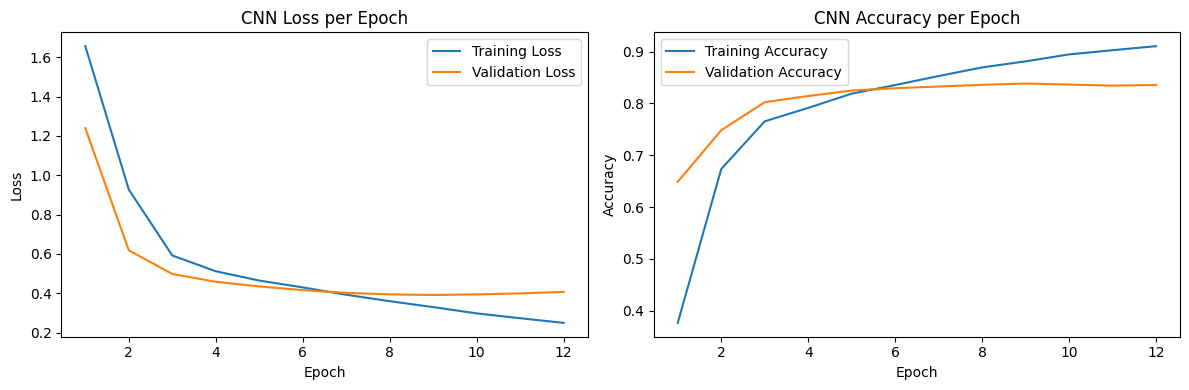

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_Multiclass_80_20/CNN_Learning_Curves.png
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step
Saved .npy probs/labels in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_Multiclass_80_20
Shapes -> p_val: (5723, 6)  p_test: (9539, 6)

FINAL TEST METRICS (CNN Multiclass):
Accuracy            : 0.8310
Precision (Macro)   : 0.8326
Recall (Macro)      : 0.8304
F1 (Macro)          : 0.8282
ROC-AUC (Macro OvR) : 0.9682
Precision (Weighted): 0.8336
Recall (Weighted)   : 0.8310
F1 (Weighted)       : 0.8290


In [21]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# Paths
DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
TRAIN_PATH = os.path.join(DATA_DIR, "train_80_MASTER_ALLMODELS.csv")
VAL_PATH   = os.path.join(DATA_DIR, "val_from_train_MASTER_ALLMODELS.csv")
TEST_PATH  = os.path.join(DATA_DIR, "test_20_MASTER_ALLMODELS.csv")
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

RESULTS_DIR = str(MODEL_DIRS["CNN"])
os.makedirs(RESULTS_DIR, exist_ok=True)

# Reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Load data
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

if "text_dl" in train_df.columns:
    TEXT_COL = "text_dl"
elif "text_ml" in train_df.columns:
    TEXT_COL = "text_ml"
else:
    TEXT_COL = "tweet_text"

for df in (train_df, val_df, test_df):
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    df["label"] = df["label"].astype(int)

X_train, y_train = train_df[TEXT_COL].values, train_df["label"].values
X_val,   y_val   = val_df[TEXT_COL].values,   val_df["label"].values
X_test,  y_test  = test_df[TEXT_COL].values,  test_df["label"].values

# Label names
if os.path.exists(ID2LABEL_PATH):
    id2label = json.load(open(ID2LABEL_PATH))
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    # Fallback: infer from file (order may differ)
    if "cyberbullying_type" in train_df.columns:
        label_names = list(pd.Series(train_df["cyberbullying_type"].unique()).sort_values())
    else:
        label_names = [f"class_{i}" for i in sorted(np.unique(y_train))]

K = len(label_names)
print("Text column:", TEXT_COL)
print("Classes K:", K, "| label_names:", label_names)
print("Sizes -> Train/Val/Test:", len(X_train), len(X_val), len(X_test))

# Tokenize + Pad
VOCAB_SIZE = 30000
MAX_SEQ = 120
OOV = "<UNK>"

tok = keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV)
tok.fit_on_texts(X_train)

Xtr = pad_sequences(tok.texts_to_sequences(X_train), maxlen=MAX_SEQ, padding="post", truncating="post")
Xva = pad_sequences(tok.texts_to_sequences(X_val),   maxlen=MAX_SEQ, padding="post", truncating="post")
Xte = pad_sequences(tok.texts_to_sequences(X_test),  maxlen=MAX_SEQ, padding="post", truncating="post")

ytr_oh = keras.utils.to_categorical(y_train, num_classes=K)
yva_oh = keras.utils.to_categorical(y_val,   num_classes=K)
yte_oh = keras.utils.to_categorical(y_test,  num_classes=K)

# Build CNN (Multiclass)
EMB_DIM = 128

cnn = keras.Sequential([
    layers.Input(shape=(MAX_SEQ,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMB_DIM),
    layers.Conv1D(128, kernel_size=3, activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(K, activation="softmax")
])

cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

# Train
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = cnn.fit(
    Xtr, ytr_oh,
    validation_data=(Xva, yva_oh),
    epochs=15,
    batch_size=128,
    callbacks=[early],
    verbose=1
)

# Save learning curves (Loss + Accuracy per epoch)
epochs = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history.history["loss"], label="Training Loss")
ax[0].plot(epochs, history.history["val_loss"], label="Validation Loss")
ax[0].set_title("CNN Loss per Epoch")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(epochs, history.history["accuracy"], label="Training Accuracy")
ax[1].plot(epochs, history.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("CNN Accuracy per Epoch")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
curve_path = os.path.join(RESULTS_DIR, "CNN_Learning_Curves.png")
plt.savefig(curve_path, dpi=300)
plt.show()
plt.close()
print("Saved:", curve_path)

# ---------------------------
# Predict (VAL + TEST) and save .npy for ensembles
# ---------------------------
p_val  = cnn.predict(Xva, batch_size=256)   # shape [N_val, K]
p_test = cnn.predict(Xte, batch_size=256)   # shape [N_test, K]

np.save(os.path.join(RESULTS_DIR, "val_probs_cnn.npy"),  p_val)
np.save(os.path.join(RESULTS_DIR, "test_probs_cnn.npy"), p_test)
np.save(os.path.join(RESULTS_DIR, "val_labels.npy"),     y_val)
np.save(os.path.join(RESULTS_DIR, "test_labels.npy"),    y_test)
print("Saved .npy probs/labels in:", RESULTS_DIR)
print("Shapes -> p_val:", p_val.shape, " p_test:", p_test.shape)

# Metrics on TEST
y_pred = np.argmax(p_test, axis=1)

acc  = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec_macro  = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro   = f1_score(y_test, y_pred, average="macro", zero_division=0)

prec_w = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec_w  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_w   = f1_score(y_test, y_pred, average="weighted", zero_division=0)

# ROC-AUC (Macro OvR)
y_test_bin = label_binarize(y_test, classes=list(range(K)))
roc_auc_macro = auc_val = None
try:
    roc_auc_macro = auc_val = tf.keras.metrics.AUC(
        multi_label=True, num_labels=K, curve="ROC", summation_method="interpolation"
    )
    auc_val.update_state(y_test_bin, p_test)
    roc_auc_macro = float(auc_val.result().numpy())
except Exception:
    from sklearn.metrics import roc_auc_score
    roc_auc_macro = roc_auc_score(y_test_bin, p_test, average="macro", multi_class="ovr")

print("\nFINAL TEST METRICS (CNN Multiclass):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {prec_macro:.4f}")
print(f"Recall (Macro)      : {rec_macro:.4f}")
print(f"F1 (Macro)          : {f1_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {roc_auc_macro:.4f}")
print(f"Precision (Weighted): {prec_w:.4f}")
print(f"Recall (Weighted)   : {rec_w:.4f}")
print(f"F1 (Weighted)       : {f1_w:.4f}")



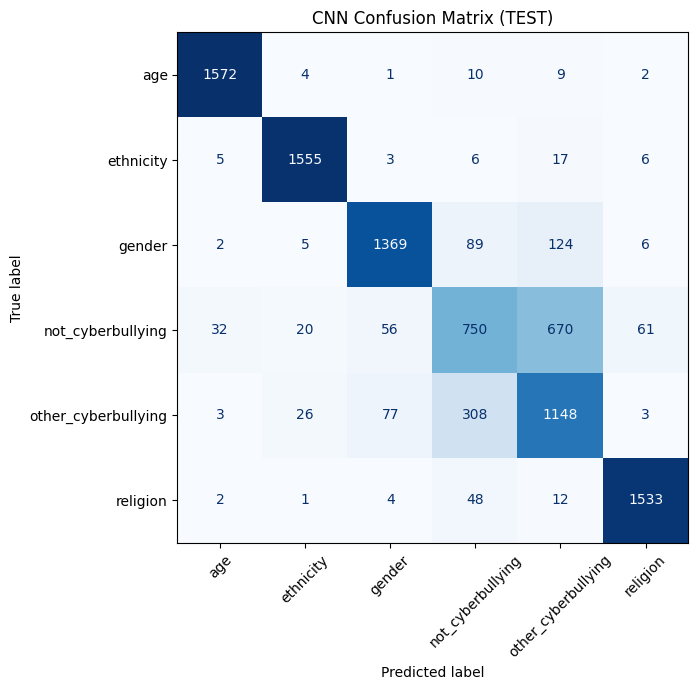

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_Multiclass_80_20/CNN_Confusion_Matrix_TEST.png


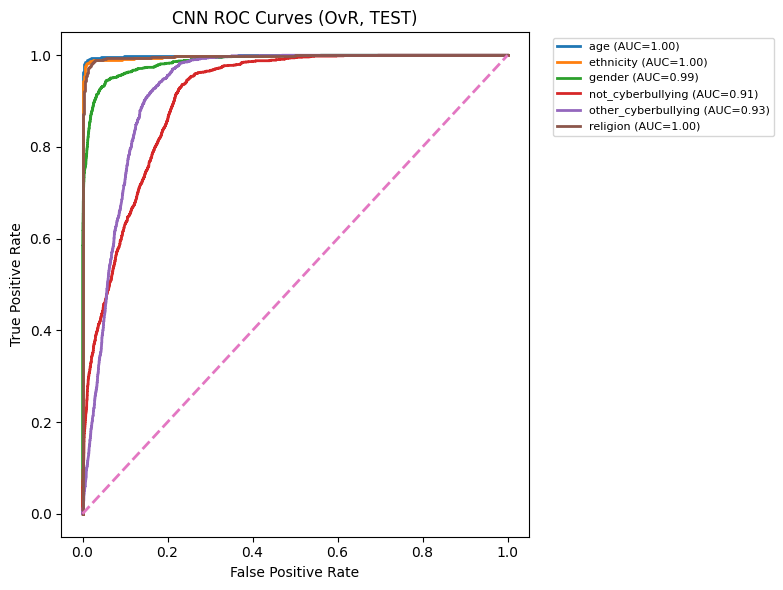

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_Multiclass_80_20/CNN_ROC_OVR_TEST.png
Saved metrics row: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_Multiclass_80_20/CNN_multiclass_performance.csv
Saved tokenizer: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_Multiclass_80_20/tokenizer_cnn.json


In [22]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("CNN Confusion Matrix (TEST)")
plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "CNN_Confusion_Matrix_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)

# ROC Curves (OvR)
plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], p_test[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
roc_path = os.path.join(RESULTS_DIR, "CNN_ROC_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)

row = pd.DataFrame([{
    "Model": "CNN",
    "Accuracy": acc,
    "Precision (Macro)": prec_macro,
    "Recall (Macro)": rec_macro,
    "F1 (Macro)": f1_macro,
    "ROC-AUC (Macro OvR)": roc_auc_macro,
    "Precision (Weighted)": prec_w,
    "Recall (Weighted)": rec_w,
    "F1 (Weighted)": f1_w
}])

out_csv = os.path.join(RESULTS_DIR, "CNN_multiclass_performance.csv")
row.to_csv(out_csv, index=False)
print("Saved metrics row:", out_csv)

# save tokenizer for reuse
tok_json = tok.to_json()
with open(os.path.join(RESULTS_DIR, "tokenizer_cnn.json"), "w") as f:
    f.write(tok_json)
print("Saved tokenizer:", os.path.join(RESULTS_DIR, "tokenizer_cnn.json"))

#CNN WITH Glove

Text column: text_ml
Classes K: 6 | label_names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Sizes -> Train/Val/Test: 32430 5723 9539
Word index size: 42638
Found incomplete or corrupted zip. Removing GLOVE_ZIP...
/content/glove.6B.z 100%[===================>] 822.24M  51.8MB/s    in 17s     
Extracting GloVe embeddings...
GloVe embeddings ready: /content/glove.6B.100d.txt
Loading GloVe vectors...
Loaded vectors: 400001
GloVe hits: 20426, misses: 9573, hit-rate: 0.681
Saved embedding matrix.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 120, 100)       │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 120, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 118, 128)       │        38,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,055,814 (11.66 MB)

 Trainable params: 55,814 (218.02 KB)

 Non-trainable params: 3,000,000 (11.44 MB)

Epoch 1/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.2700 - loss: 1.7817 - val_accuracy: 0.5915 - val_loss: 1.3390
Epoch 2/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5062 - loss: 1.2931 - val_accuracy: 0.6979 - val_loss: 0.8853
Epoch 3/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6200 - loss: 0.9967 - val_accuracy: 0.7388 - val_loss: 0.7253
Epoch 4/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6738 - loss: 0.8603 - val_accuracy: 0.7667 - val_loss: 0.6440
Epoch 5/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7027 - loss: 0.7809 - val_accuracy: 0.7802 - val_loss: 0.5918
Epoch 6/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7227 - loss: 0.7246 - val_accuracy: 0.7867 - val_loss: 0.5591
Epoch 7/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7358 - loss: 0.6833 - val_accuracy: 0.7950 - val_loss: 0.5349
Epoch 8/80
254/254 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7456 - loss: 0.6559 - val_accuracy

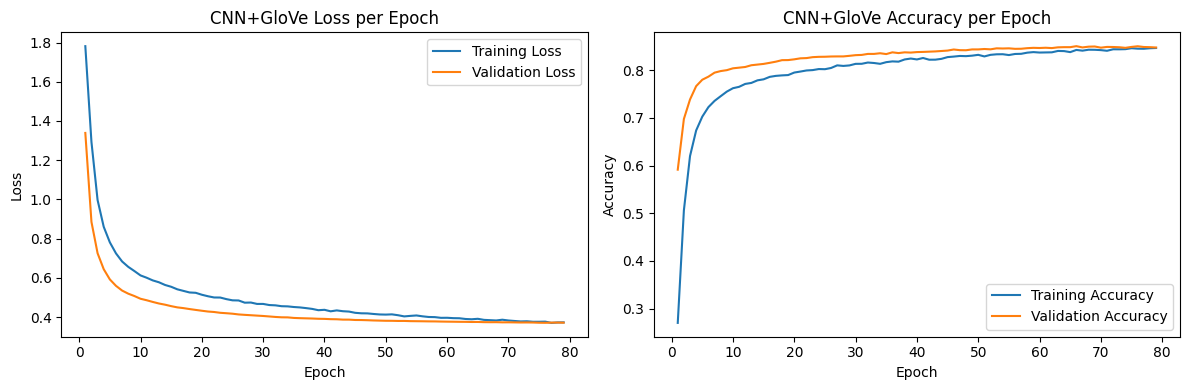

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20/CNN_GloVe_Learning_Curves.png
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
Saved .npy probs/labels in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20

FINAL TEST METRICS (CNN+GloVe Multiclass):
Accuracy            : 0.8418
Precision (Macro)   : 0.8477
Recall (Macro)      : 0.8414
F1 (Macro)          : 0.8388
ROC-AUC (Macro OvR) : 0.9723
Precision (Weighted): 0.8486
Recall (Weighted)   : 0.8418
F1 (Weighted)       : 0.8395


In [40]:
import os, json, zipfile, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# Paths (EDIT if needed)
DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
TRAIN_PATH = os.path.join(DATA_DIR, "train_80_MASTER_ALLMODELS.csv")
VAL_PATH   = os.path.join(DATA_DIR, "val_from_train_MASTER_ALLMODELS.csv")
TEST_PATH  = os.path.join(DATA_DIR, "test_20_MASTER_ALLMODELS.csv")
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

RESULTS_DIR = str(MODEL_DIRS["CNN_GLOVE"])
os.makedirs(RESULTS_DIR, exist_ok=True)

# GloVe config
GLOVE_NAME = "glove.6B.100d"
GLOVE_DIM  = 100
GLOVE_ZIP  = "/content/glove.6B.zip"
GLOVE_TXT  = f"/content/{GLOVE_NAME}.txt"

# Reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Load data
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

if "text_dl" in train_df.columns:
    TEXT_COL = "text_dl"
elif "text_ml" in train_df.columns:
    TEXT_COL = "text_ml"
else:
    TEXT_COL = "tweet_text"

for df in (train_df, val_df, test_df):
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    df["label"] = df["label"].astype(int)

X_train, y_train = train_df[TEXT_COL].values, train_df["label"].values
X_val,   y_val   = val_df[TEXT_COL].values,   val_df["label"].values
X_test,  y_test  = test_df[TEXT_COL].values,  test_df["label"].values

# Label names
if os.path.exists(ID2LABEL_PATH):
    id2label = json.load(open(ID2LABEL_PATH))
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    label_names = [f"class_{i}" for i in sorted(np.unique(y_train))]

K = len(label_names)
print("Text column:", TEXT_COL)
print("Classes K:", K, "| label_names:", label_names)
print("Sizes -> Train/Val/Test:", len(X_train), len(X_val), len(X_test))

# Tokenize + Pad
VOCAB_SIZE = 30000
MAX_SEQ = 120
OOV = "<UNK>"

tok = keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV)
tok.fit_on_texts(X_train)

Xtr = pad_sequences(tok.texts_to_sequences(X_train), maxlen=MAX_SEQ, padding="post", truncating="post")
Xva = pad_sequences(tok.texts_to_sequences(X_val),   maxlen=MAX_SEQ, padding="post", truncating="post")
Xte = pad_sequences(tok.texts_to_sequences(X_test),  maxlen=MAX_SEQ, padding="post", truncating="post")

ytr_oh = keras.utils.to_categorical(y_train, num_classes=K)
yva_oh = keras.utils.to_categorical(y_val,   num_classes=K)
yte_oh = keras.utils.to_categorical(y_test,  num_classes=K)

word_index = tok.word_index
print("Word index size:", len(word_index))

# Download + Extract GloVe

GLOVE_URL = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"

def is_valid_zip(path):
    if not os.path.exists(path) or os.path.getsize(path) < 50 * 1024 * 1024:
        return False
    try:
        with zipfile.ZipFile(path, "r") as test_z:
            return test_z.testzip() is None
    except Exception:
        return False

if os.path.exists(GLOVE_ZIP) and not is_valid_zip(GLOVE_ZIP):
    print("Found incomplete or corrupted zip. Removing GLOVE_ZIP...")
    os.remove(GLOVE_ZIP)

if not os.path.exists(GLOVE_ZIP):
    print("Downloading GloVe embeddings from HuggingFace mirror...")
    !wget -q --show-progress -O "$GLOVE_ZIP" "$GLOVE_URL"

if not os.path.exists(GLOVE_TXT):
    print("Extracting GloVe embeddings...")
    if not is_valid_zip(GLOVE_ZIP):
        raise RuntimeError("The downloaded file is corrupted or not a valid zip archive. Please try re-running.")
    with zipfile.ZipFile(GLOVE_ZIP, "r") as z:
        z.extract(GLOVE_NAME + ".txt", path="/content")

print("GloVe embeddings ready:", GLOVE_TXT)

# Load embeddings into dict
print("Loading GloVe vectors...")
embeddings_index = {}
with open(GLOVE_TXT, "r", encoding="utf-8") as f:
    for line in f:
        values = line.rstrip().split(" ")
        word = values[0]
        vec = np.asarray(values[1:], dtype="float32")
        if vec.shape[0] == GLOVE_DIM:
            embeddings_index[word] = vec

print("Loaded vectors:", len(embeddings_index))

# Build embedding matrix

num_words = min(VOCAB_SIZE, len(word_index) + 1)
embedding_matrix = np.random.normal(scale=0.6, size=(num_words, GLOVE_DIM)).astype("float32")
embedding_matrix[0] = np.zeros((GLOVE_DIM,), dtype="float32")

hits, misses = 0, 0
for word, i in word_index.items():
    if i >= num_words:
        continue
    vec = embeddings_index.get(word)
    if vec is not None:
        embedding_matrix[i] = vec
        hits += 1
    else:
        misses += 1

print(f"GloVe hits: {hits}, misses: {misses}, hit-rate: {hits/(hits+misses+1e-9):.3f}")

# Save matrix for reproducibility
np.save(os.path.join(RESULTS_DIR, f"glove_embedding_matrix_{GLOVE_NAME}.npy"), embedding_matrix)
print("Saved embedding matrix.")

# Build CNN + GloVe (Multiclass)
LEARNING_RATE = 1e-4

cnn = keras.Sequential([
    layers.Input(shape=(MAX_SEQ,)),
    layers.Embedding(
        input_dim=num_words,
        output_dim=GLOVE_DIM,
        weights=[embedding_matrix],
        input_length=MAX_SEQ,
        trainable=False
    ),
    layers.SpatialDropout1D(0.2),
    layers.Conv1D(128, kernel_size=3, activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(K, activation="softmax")
])

cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

# Train (Early stopping)
early = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn.fit(
    Xtr, ytr_oh,
    validation_data=(Xva, yva_oh),
    epochs=80,
    batch_size=128,
    callbacks=[early],
    verbose=1
)

# Save learning curves

epochs = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history.history["loss"], label="Training Loss")
ax[0].plot(epochs, history.history["val_loss"], label="Validation Loss")
ax[0].set_title("CNN+GloVe Loss per Epoch")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(epochs, history.history["accuracy"], label="Training Accuracy")
ax[1].plot(epochs, history.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("CNN+GloVe Accuracy per Epoch")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
curve_path = os.path.join(RESULTS_DIR, "CNN_GloVe_Learning_Curves.png")
plt.savefig(curve_path, dpi=300)
plt.show()
plt.close()
print("Saved:", curve_path)

# Predict (VAL + TEST) and save

p_val  = cnn.predict(Xva, batch_size=256)
p_test = cnn.predict(Xte, batch_size=256)

np.save(os.path.join(RESULTS_DIR, "val_probs_cnn_glove.npy"),  p_val)
np.save(os.path.join(RESULTS_DIR, "test_probs_cnn_glove.npy"), p_test)
np.save(os.path.join(RESULTS_DIR, "val_labels.npy"),     y_val)
np.save(os.path.join(RESULTS_DIR, "test_labels.npy"),    y_test)
print("Saved .npy probs/labels in:", RESULTS_DIR)

# Metrics on TEST
y_pred = np.argmax(p_test, axis=1)

acc  = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec_macro  = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro   = f1_score(y_test, y_pred, average="macro", zero_division=0)

prec_w = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec_w  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_w   = f1_score(y_test, y_pred, average="weighted", zero_division=0)

y_test_bin = label_binarize(y_test, classes=list(range(K)))
from sklearn.metrics import roc_auc_score
roc_auc_macro = roc_auc_score(y_test_bin, p_test, average="macro", multi_class="ovr")

print("\nFINAL TEST METRICS (CNN+GloVe Multiclass):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {prec_macro:.4f}")
print(f"Recall (Macro)      : {rec_macro:.4f}")
print(f"F1 (Macro)          : {f1_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {roc_auc_macro:.4f}")
print(f"Precision (Weighted): {prec_w:.4f}")
print(f"Recall (Weighted)   : {rec_w:.4f}")
print(f"F1 (Weighted)       : {f1_w:.4f}")

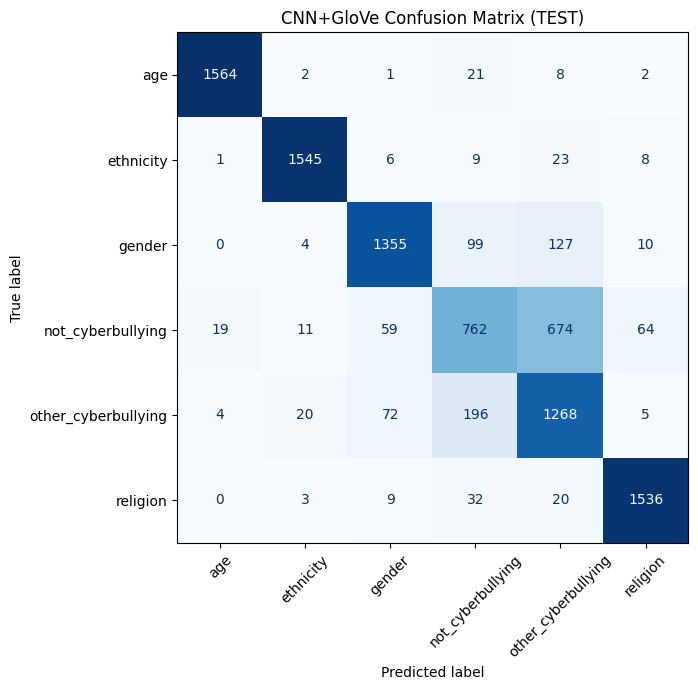

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20/CNN_GloVe_Confusion_Matrix_TEST.png


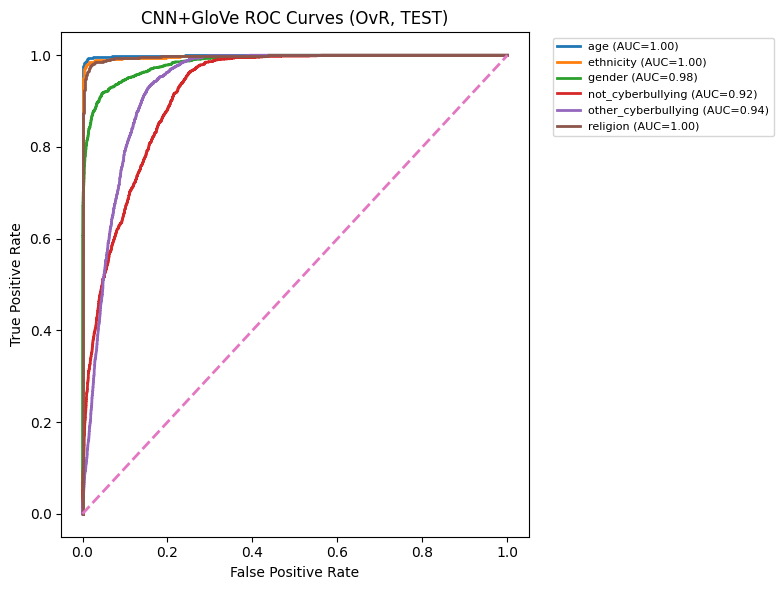

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20/CNN_GloVe_ROC_OVR_TEST.png
Saved metrics row: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20/CNN_GloVe_multiclass_performance.csv

All CNN+GloVe artifacts saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20


In [41]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("CNN+GloVe Confusion Matrix (TEST)")
plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "CNN_GloVe_Confusion_Matrix_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)

# ROC Curves (OvR)

plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], p_test[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN+GloVe ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
roc_path = os.path.join(RESULTS_DIR, "CNN_GloVe_ROC_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)

# Save a one-row results table (CSV)
row = pd.DataFrame([{
    "Model": f"CNN+{GLOVE_NAME} (frozen)",
    "Accuracy": acc,
    "Precision (Macro)": prec_macro,
    "Recall (Macro)": rec_macro,
    "F1 (Macro)": f1_macro,
    "ROC-AUC (Macro OvR)": roc_auc_macro,
    "Precision (Weighted)": prec_w,
    "Recall (Weighted)": rec_w,
    "F1 (Weighted)": f1_w,
    "Vocab_Size": VOCAB_SIZE,
    "Max_Seq": MAX_SEQ,
    "GloVe": GLOVE_NAME,
    "Embedding_Trainable": False,
    "LR": LEARNING_RATE
}])

out_csv = os.path.join(RESULTS_DIR, "CNN_GloVe_multiclass_performance.csv")
row.to_csv(out_csv, index=False)
print("Saved metrics row:", out_csv)

# Save tokenizer JSON for reuse
tok_json = tok.to_json()
with open(os.path.join(RESULTS_DIR, "tokenizer_cnn.json"), "w") as f:
    f.write(tok_json)

print("\nAll CNN+GloVe artifacts saved in:", RESULTS_DIR)

#BILSTM

Text column: text_ml
Classes K: 6 | label_names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Sizes -> Train/Val/Test: 32430 5723 9539


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 120, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 120, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,136,838 (15.78 MB)

 Trainable params: 4,136,838 (15.78 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.2742 - loss: 1.6342 - val_accuracy: 0.4068 - val_loss: 1.3317
Epoch 2/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.5118 - loss: 1.1177 - val_accuracy: 0.6493 - val_loss: 0.8421
Epoch 3/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.7104 - loss: 0.6976 - val_accuracy: 0.7547 - val_loss: 0.5561
Epoch 4/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7635 - loss: 0.5298 - val_accuracy: 0.7728 - val_loss: 0.4983
Epoch 5/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7814 - loss: 0.4695 - val_accuracy: 0.7991 - val_loss: 0.4769
Epoch 6/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7946 - loss: 0.4303 - val_accuracy: 0.8076 - val_loss: 0.4526
Epoch 7/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.8093 - loss: 0.4039 - val_accuracy: 0.8090 - val_loss: 0.4439
Epoch 8/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.8244 - loss: 0.3748 - val_acc

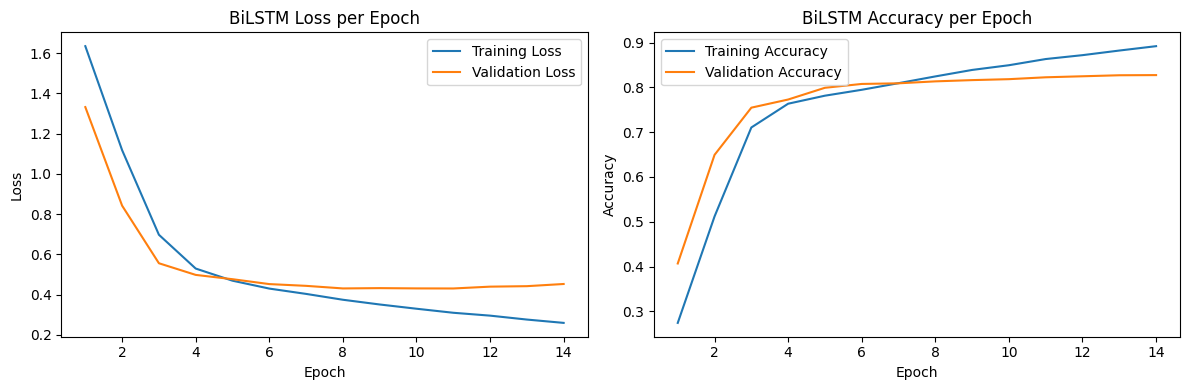

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_Multiclass_80_20/BiLSTM_Learning_Curves.png
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Saved .npy probs/labels in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_Multiclass_80_20

FINAL TEST METRICS (BiLSTM Multiclass):
Accuracy            : 0.8203
Precision (Macro)   : 0.8286
Recall (Macro)      : 0.8199
F1 (Macro)          : 0.8119
ROC-AUC (Macro OvR) : 0.9639
Precision (Weighted): 0.8297
Recall (Weighted)   : 0.8203
F1 (Weighted)       : 0.8127


In [42]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Paths
DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
TRAIN_PATH = os.path.join(DATA_DIR, "train_80_MASTER_ALLMODELS.csv")
VAL_PATH   = os.path.join(DATA_DIR, "val_from_train_MASTER_ALLMODELS.csv")
TEST_PATH  = os.path.join(DATA_DIR, "test_20_MASTER_ALLMODELS.csv")
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

RESULTS_DIR = str(MODEL_DIRS["BILSTM"])
os.makedirs(RESULTS_DIR, exist_ok=True)

# Reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Load data
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

# Pick text column automatically
if "text_dl" in train_df.columns:
    TEXT_COL = "text_dl"
elif "text_ml" in train_df.columns:
    TEXT_COL = "text_ml"
else:
    TEXT_COL = "tweet_text"

for df in (train_df, val_df, test_df):
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    df["label"] = df["label"].astype(int)

X_train, y_train = train_df[TEXT_COL].values, train_df["label"].values
X_val,   y_val   = val_df[TEXT_COL].values,   val_df["label"].values
X_test,  y_test  = test_df[TEXT_COL].values,  test_df["label"].values

# Label names
if os.path.exists(ID2LABEL_PATH):
    id2label = json.load(open(ID2LABEL_PATH))
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    label_names = [f"class_{i}" for i in sorted(np.unique(y_train))]

K = len(label_names)
print("Text column:", TEXT_COL)
print("Classes K:", K, "| label_names:", label_names)
print("Sizes -> Train/Val/Test:", len(X_train), len(X_val), len(X_test))

# Tokenize + Pad
VOCAB_SIZE = 30000
MAX_SEQ = 120
OOV = "<UNK>"

tok = keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV)
tok.fit_on_texts(X_train)

Xtr = pad_sequences(tok.texts_to_sequences(X_train), maxlen=MAX_SEQ, padding="post", truncating="post")
Xva = pad_sequences(tok.texts_to_sequences(X_val),   maxlen=MAX_SEQ, padding="post", truncating="post")
Xte = pad_sequences(tok.texts_to_sequences(X_test),  maxlen=MAX_SEQ, padding="post", truncating="post")

ytr_oh = keras.utils.to_categorical(y_train, num_classes=K)
yva_oh = keras.utils.to_categorical(y_val,   num_classes=K)
yte_oh = keras.utils.to_categorical(y_test,  num_classes=K)

# Save tokenizer for reuse
with open(os.path.join(RESULTS_DIR, "tokenizer_bilstm.json"), "w") as f:
    f.write(tok.to_json())

# Build BiLSTM model
EMB_DIM = 128
LSTM_UNITS = 128
LEARNING_RATE = 1e-4

model = keras.Sequential([
    layers.Input(shape=(MAX_SEQ,)),
    layers.Embedding(VOCAB_SIZE, EMB_DIM),
    layers.SpatialDropout1D(0.2),

    layers.Bidirectional(layers.LSTM(LSTM_UNITS, return_sequences=False)),
    layers.Dropout(0.5),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(K, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train (Early stopping)
early = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    #min_delta=1e-4,
    restore_best_weights=True
)

history = model.fit(
    Xtr, ytr_oh,
    validation_data=(Xva, yva_oh),
    epochs=15,                # allow enough room; early stop will decide
    batch_size=128,
    callbacks=[early],
    verbose=1
)

# Learning curves
epochs = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history.history["loss"], label="Training Loss")
ax[0].plot(epochs, history.history["val_loss"], label="Validation Loss")
ax[0].set_title("BiLSTM Loss per Epoch")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(epochs, history.history["accuracy"], label="Training Accuracy")
ax[1].plot(epochs, history.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("BiLSTM Accuracy per Epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
curve_path = os.path.join(RESULTS_DIR, "BiLSTM_Learning_Curves.png")
plt.savefig(curve_path, dpi=300)
plt.show()
plt.close()
print("Saved:", curve_path)

# Predict (VAL + TEST)
p_val  = model.predict(Xva, batch_size=256)  # [N_val, K]
p_test = model.predict(Xte, batch_size=256)  # [N_test, K]

np.save(os.path.join(RESULTS_DIR, "val_probs_bilstm.npy"),  p_val)
np.save(os.path.join(RESULTS_DIR, "test_probs_bilstm.npy"), p_test)
np.save(os.path.join(RESULTS_DIR, "val_labels.npy"), y_val)
np.save(os.path.join(RESULTS_DIR, "test_labels.npy"), y_test)
print("Saved .npy probs/labels in:", RESULTS_DIR)

# Metrics (TEST)
y_pred = np.argmax(p_test, axis=1)

acc  = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec_macro  = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro   = f1_score(y_test, y_pred, average="macro", zero_division=0)

prec_w = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec_w  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_w   = f1_score(y_test, y_pred, average="weighted", zero_division=0)

# ROC-AUC (Macro OvR)
y_test_bin = label_binarize(y_test, classes=list(range(K)))
roc_auc_macro = roc_auc_score(y_test_bin, p_test, average="macro", multi_class="ovr")

print("\nFINAL TEST METRICS (BiLSTM Multiclass):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {prec_macro:.4f}")
print(f"Recall (Macro)      : {rec_macro:.4f}")
print(f"F1 (Macro)          : {f1_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {roc_auc_macro:.4f}")
print(f"Precision (Weighted): {prec_w:.4f}")
print(f"Recall (Weighted)   : {rec_w:.4f}")
print(f"F1 (Weighted)       : {f1_w:.4f}")



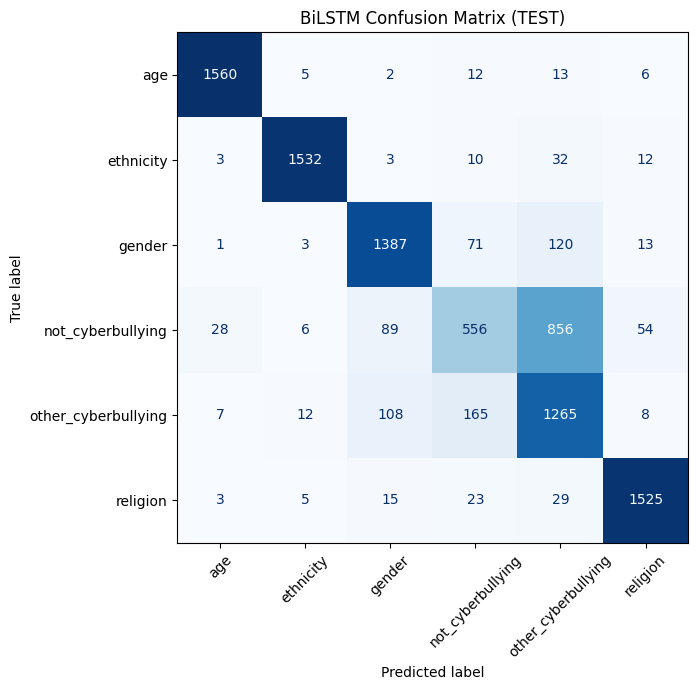

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_Multiclass_80_20/BiLSTM_Confusion_Matrix_TEST.png


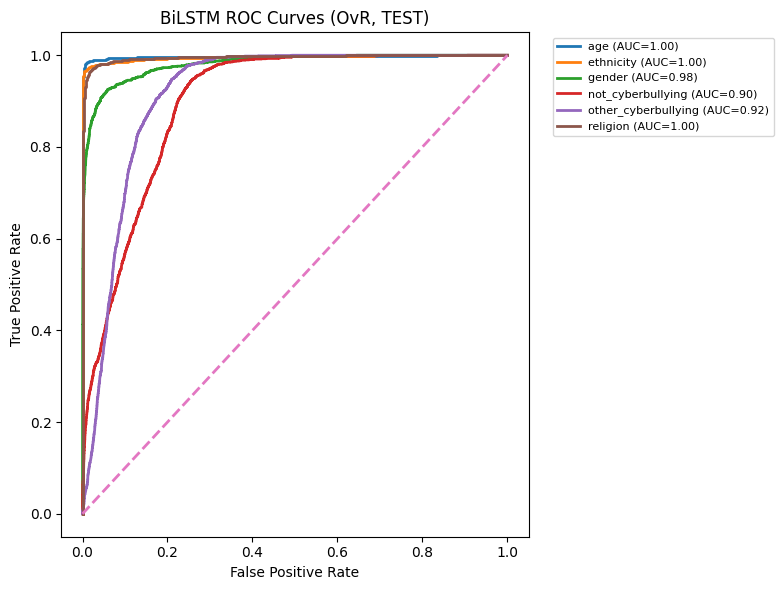

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_Multiclass_80_20/BiLSTM_ROC_OVR_TEST.png
Saved metrics row: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_Multiclass_80_20/BiLSTM_multiclass_performance.csv

All BiLSTM artifacts saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_Multiclass_80_20


In [43]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("BiLSTM Confusion Matrix (TEST)")
plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "BiLSTM_Confusion_Matrix_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)

# ROC Curves (OvR)
plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], p_test[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("BiLSTM ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
roc_path = os.path.join(RESULTS_DIR, "BiLSTM_ROC_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)

# Save one-row results table (CSV)
row = pd.DataFrame([{
    "Model": "BiLSTM (random embeddings)",
    "Accuracy": acc,
    "Precision (Macro)": prec_macro,
    "Recall (Macro)": rec_macro,
    "F1 (Macro)": f1_macro,
    "ROC-AUC (Macro OvR)": roc_auc_macro,
    "Precision (Weighted)": prec_w,
    "Recall (Weighted)": rec_w,
    "F1 (Weighted)": f1_w,
    "Vocab_Size": VOCAB_SIZE,
    "Max_Seq": MAX_SEQ,
    "Emb_Dim": EMB_DIM,
    "LSTM_Units": LSTM_UNITS,
    "LR": LEARNING_RATE
}])

out_csv = os.path.join(RESULTS_DIR, "BiLSTM_multiclass_performance.csv")
row.to_csv(out_csv, index=False)
print("Saved metrics row:", out_csv)

print("\nAll BiLSTM artifacts saved in:", RESULTS_DIR)

#BILSTM Glove

Text column: text_ml
Classes K: 6 | label_names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Sizes -> Train/Val/Test: 32430 5723 9539
Loading GloVe vectors...
GloVe hits: 20426, misses: 9573, hit-rate: 0.681


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 120, 100)       │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (None, 120, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 256)            │       234,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,268,166 (12.47 MB)

 Trainable params: 268,166 (1.02 MB)

 Non-trainable params: 3,000,000 (11.44 MB)

Epoch 1/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.3429 - loss: 1.5905 - val_accuracy: 0.6138 - val_loss: 0.9922
Epoch 2/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.6152 - loss: 0.9622 - val_accuracy: 0.7288 - val_loss: 0.6679
Epoch 3/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.6853 - loss: 0.7787 - val_accuracy: 0.7496 - val_loss: 0.6017
Epoch 4/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.7074 - loss: 0.7066 - val_accuracy: 0.7622 - val_loss: 0.5638
Epoch 5/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.7246 - loss: 0.6585 - val_accuracy: 0.7674 - val_loss: 0.5515
Epoch 6/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.7342 - loss: 0.6299 - val_accuracy: 0.7730 - val_loss: 0.5273
Epoch 7/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.7411 - loss: 0.6097 - val_accuracy: 0.7779 - val_loss: 0.5092
Epoch 8/50
254/254 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.7564 - loss: 0.5776 - val_acc

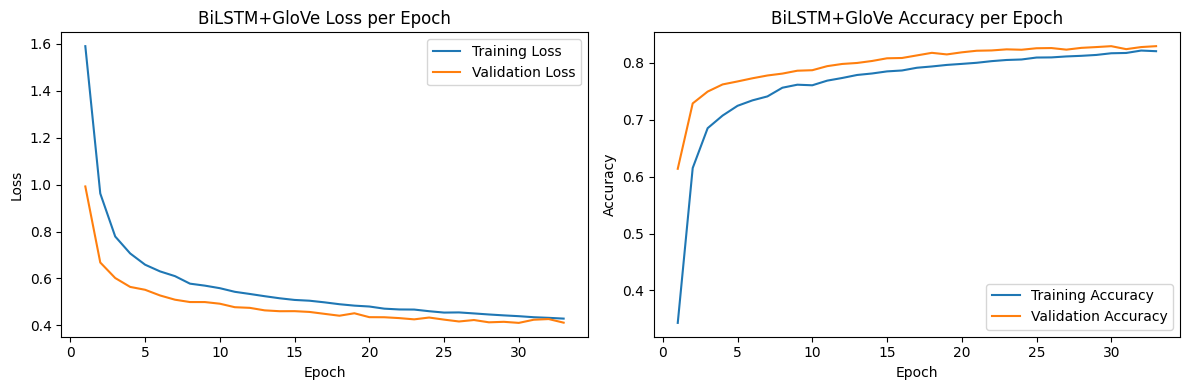

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_GloVe_Multiclass_80_20/BiLSTM_GloVe_Learning_Curves.png
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Saved .npy probs/labels in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_GloVe_Multiclass_80_20

FINAL TEST METRICS (BiLSTM+GloVe Multiclass):
Accuracy            : 0.8251
Precision (Macro)   : 0.8364
Recall (Macro)      : 0.8249
F1 (Macro)          : 0.8189
ROC-AUC (Macro OvR) : 0.9687
Precision (Weighted): 0.8374
Recall (Weighted)   : 0.8251
F1 (Weighted)       : 0.8196


In [44]:
import os, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Path

DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
TRAIN_PATH = os.path.join(DATA_DIR, "train_80_MASTER_ALLMODELS.csv")
VAL_PATH   = os.path.join(DATA_DIR, "val_from_train_MASTER_ALLMODELS.csv")
TEST_PATH  = os.path.join(DATA_DIR, "test_20_MASTER_ALLMODELS.csv")
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

RESULTS_DIR = str(MODEL_DIRS["BILSTM_GLOVE"])
os.makedirs(RESULTS_DIR, exist_ok=True)

# GloVe config

# GloVe config
GLOVE_NAME = "glove.6B.100d"
GLOVE_DIM  = 100
GLOVE_ZIP  = "/content/glove.6B.zip"
GLOVE_TXT  = f"/content/{GLOVE_NAME}.txt"

# Reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Load data
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

if "text_dl" in train_df.columns:
    TEXT_COL = "text_dl"
elif "text_ml" in train_df.columns:
    TEXT_COL = "text_ml"
else:
    TEXT_COL = "tweet_text"

for df in (train_df, val_df, test_df):
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    df["label"] = df["label"].astype(int)

X_train, y_train = train_df[TEXT_COL].values, train_df["label"].values
X_val,   y_val   = val_df[TEXT_COL].values,   val_df["label"].values
X_test,  y_test  = test_df[TEXT_COL].values,  test_df["label"].values

# Label names
if os.path.exists(ID2LABEL_PATH):
    id2label = json.load(open(ID2LABEL_PATH))
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    label_names = [f"class_{i}" for i in sorted(np.unique(y_train))]

K = len(label_names)
print("Text column:", TEXT_COL)
print("Classes K:", K, "| label_names:", label_names)
print("Sizes -> Train/Val/Test:", len(X_train), len(X_val), len(X_test))

# Tokenize + Pad
VOCAB_SIZE = 30000
MAX_SEQ = 120
OOV = "<UNK>"

tok = keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV)
tok.fit_on_texts(X_train)

Xtr = pad_sequences(tok.texts_to_sequences(X_train), maxlen=MAX_SEQ, padding="post", truncating="post")
Xva = pad_sequences(tok.texts_to_sequences(X_val),   maxlen=MAX_SEQ, padding="post", truncating="post")
Xte = pad_sequences(tok.texts_to_sequences(X_test),  maxlen=MAX_SEQ, padding="post", truncating="post")

ytr_oh = keras.utils.to_categorical(y_train, num_classes=K)
yva_oh = keras.utils.to_categorical(y_val,   num_classes=K)
yte_oh = keras.utils.to_categorical(y_test,  num_classes=K)

# Save tokenizer
with open(os.path.join(RESULTS_DIR, "tokenizer_bilstm_glove.json"), "w") as f:
    f.write(tok.to_json())

word_index = tok.word_index
num_words = min(VOCAB_SIZE, len(word_index) + 1)

# Download + Extract GloVe
if not os.path.exists(GLOVE_ZIP):
    print("Downloading GloVe...")
    !wget -q -O "$GLOVE_ZIP" "$GLOVE_URL"
    print("Downloaded:", GLOVE_ZIP)

if not os.path.exists(GLOVE_TXT):
    print("Extracting GloVe txt...")
    with zipfile.ZipFile(GLOVE_ZIP, "r") as z:
        z.extract(GLOVE_NAME + ".txt", path="/content")
    print("Extracted:", GLOVE_TXT)

# Load embeddings + build matrix
print("Loading GloVe vectors...")
embeddings_index = {}
with open(GLOVE_TXT, "r", encoding="utf-8") as f:
    for line in f:
        vals = line.rstrip().split(" ")
        w = vals[0]
        vec = np.asarray(vals[1:], dtype="float32")
        if vec.shape[0] == GLOVE_DIM:
            embeddings_index[w] = vec

embedding_matrix = np.random.normal(scale=0.6, size=(num_words, GLOVE_DIM)).astype("float32")
embedding_matrix[0] = np.zeros((GLOVE_DIM,), dtype="float32")  # PAD

hits, misses = 0, 0
for w, i in word_index.items():
    if i >= num_words:
        continue
    vec = embeddings_index.get(w)
    if vec is not None:
        embedding_matrix[i] = vec
        hits += 1
    else:
        misses += 1

print(f"GloVe hits: {hits}, misses: {misses}, hit-rate: {hits/(hits+misses+1e-9):.3f}")
np.save(os.path.join(RESULTS_DIR, f"glove_embedding_matrix_{GLOVE_NAME}.npy"), embedding_matrix)

# BiLSTM + GloVe model
LSTM_UNITS = 128
LEARNING_RATE = 1e-4

model = keras.Sequential([
    layers.Input(shape=(MAX_SEQ,)),
    layers.Embedding(
        input_dim=num_words,
        output_dim=GLOVE_DIM,
        weights=[embedding_matrix],
        input_length=MAX_SEQ,
        trainable=False   # start frozen for fair comparison
    ),
    layers.SpatialDropout1D(0.2),
    layers.Bidirectional(layers.LSTM(LSTM_UNITS, return_sequences=False)),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(K, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train (Early stopping)
early = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    min_delta=1e-4,
    restore_best_weights=True
)

history = model.fit(
    Xtr, ytr_oh,
    validation_data=(Xva, yva_oh),
    epochs=50,
    batch_size=128,
    callbacks=[early],
    verbose=1
)

# Learning curves (SAVE)
epochs = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history.history["loss"], label="Training Loss")
ax[0].plot(epochs, history.history["val_loss"], label="Validation Loss")
ax[0].set_title("BiLSTM+GloVe Loss per Epoch")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(epochs, history.history["accuracy"], label="Training Accuracy")
ax[1].plot(epochs, history.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("BiLSTM+GloVe Accuracy per Epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
curve_path = os.path.join(RESULTS_DIR, "BiLSTM_GloVe_Learning_Curves.png")
plt.savefig(curve_path, dpi=300)
plt.show()
plt.close()
print("Saved:", curve_path)

# Predict (VAL + TEST) + Save .npy
p_val  = model.predict(Xva, batch_size=256)  # [N_val, K]
p_test = model.predict(Xte, batch_size=256)  # [N_test, K]

np.save(os.path.join(RESULTS_DIR, "val_probs_bilstm_glove.npy"),  p_val)
np.save(os.path.join(RESULTS_DIR, "test_probs_bilstm_glove.npy"), p_test)
np.save(os.path.join(RESULTS_DIR, "val_labels.npy"), y_val)
np.save(os.path.join(RESULTS_DIR, "test_labels.npy"), y_test)
print("Saved .npy probs/labels in:", RESULTS_DIR)

# Metrics (TEST)
y_pred = np.argmax(p_test, axis=1)

acc  = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec_macro  = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro   = f1_score(y_test, y_pred, average="macro", zero_division=0)

prec_w = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec_w  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_w   = f1_score(y_test, y_pred, average="weighted", zero_division=0)

y_test_bin = label_binarize(y_test, classes=list(range(K)))
roc_auc_macro = roc_auc_score(y_test_bin, p_test, average="macro", multi_class="ovr")

print("\nFINAL TEST METRICS (BiLSTM+GloVe Multiclass):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {prec_macro:.4f}")
print(f"Recall (Macro)      : {rec_macro:.4f}")
print(f"F1 (Macro)          : {f1_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {roc_auc_macro:.4f}")
print(f"Precision (Weighted): {prec_w:.4f}")
print(f"Recall (Weighted)   : {rec_w:.4f}")
print(f"F1 (Weighted)       : {f1_w:.4f}")



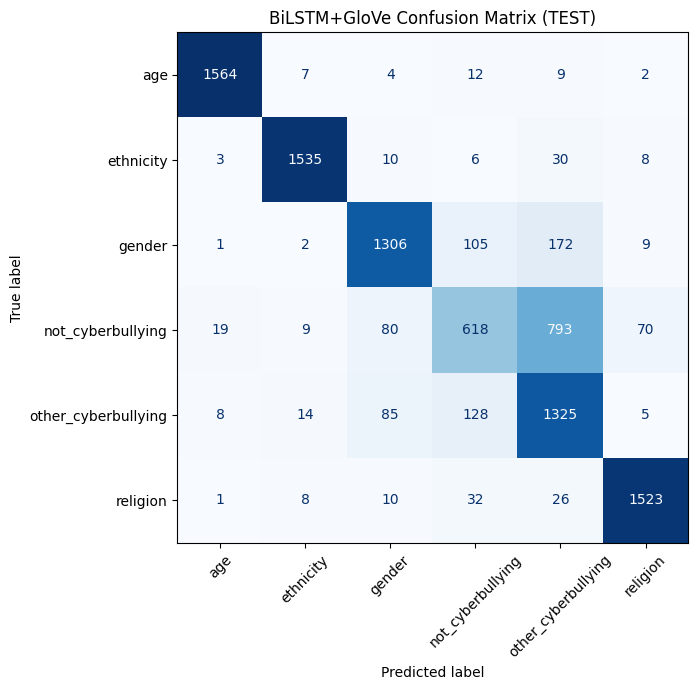

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_GloVe_Multiclass_80_20/BiLSTM_GloVe_Confusion_Matrix_TEST.png


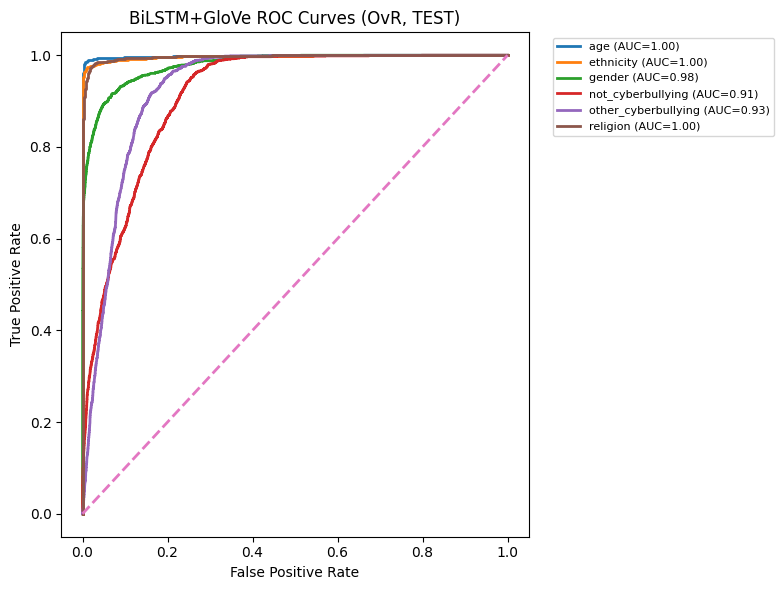

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_GloVe_Multiclass_80_20/BiLSTM_GloVe_ROC_OVR_TEST.png
Saved metrics row: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_GloVe_Multiclass_80_20/BiLSTM_GloVe_multiclass_performance.csv

All BiLSTM+GloVe artifacts saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BiLSTM_GloVe_Multiclass_80_20


In [45]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("BiLSTM+GloVe Confusion Matrix (TEST)")
plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "BiLSTM_GloVe_Confusion_Matrix_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)

# ROC Curves (OvR)
plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], p_test[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("BiLSTM+GloVe ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
roc_path = os.path.join(RESULTS_DIR, "BiLSTM_GloVe_ROC_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)


row = pd.DataFrame([{
    "Model": f"BiLSTM+{GLOVE_NAME} (frozen)",
    "Accuracy": acc,
    "Precision (Macro)": prec_macro,
    "Recall (Macro)": rec_macro,
    "F1 (Macro)": f1_macro,
    "ROC-AUC (Macro OvR)": roc_auc_macro,
    "Precision (Weighted)": prec_w,
    "Recall (Weighted)": rec_w,
    "F1 (Weighted)": f1_w,
    "Vocab_Size": VOCAB_SIZE,
    "Max_Seq": MAX_SEQ,
    "GloVe": GLOVE_NAME,
    "Embedding_Trainable": False,
    "LSTM_Units": LSTM_UNITS,
    "LR": LEARNING_RATE
}])

out_csv = os.path.join(RESULTS_DIR, "BiLSTM_GloVe_multiclass_performance.csv")
row.to_csv(out_csv, index=False)
print("Saved metrics row:", out_csv)

print("\nAll BiLSTM+GloVe artifacts saved in:", RESULTS_DIR)

#BERT Training

In [46]:
pip install -U "transformers>=4.44" "datasets>=2.18" "accelerate>=0.26" "evaluate>=0.4"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 32.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 31.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 65.3 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.15.0
    Uninstalling accelerate-1.15.0:
      Successfully uninstalled accelerate-1.15.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [accelerate]
ERROR: pip's dependency resolver does no

In [13]:
import os, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    set_seed,
    TrainerCallback
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from collections import defaultdict


# PATHS
DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
TRAIN_PATH = os.path.join(DATA_DIR, "train_80_MASTER_ALLMODELS.csv")
VAL_PATH   = os.path.join(DATA_DIR, "val_from_train_MASTER_ALLMODELS.csv")
TEST_PATH  = os.path.join(DATA_DIR, "test_20_MASTER_ALLMODELS.csv")
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

if "MODEL_DIRS" in globals():
    RESULTS_DIR = str(MODEL_DIRS["BERT"])
else:
    RESULTS_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20"

os.makedirs(RESULTS_DIR, exist_ok=True)

TEXT_COL: text_trf
K: 6 | label_names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Sizes -> Train/Val/Test: 32430 5723 9539


Map:   0%|          | 0/32430 [00:00<?, ? examples/s]

Map:   0%|          | 0/5723 [00:00<?, ? examples/s]

Map:   0%|          | 0/9539 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

BERT training complete.


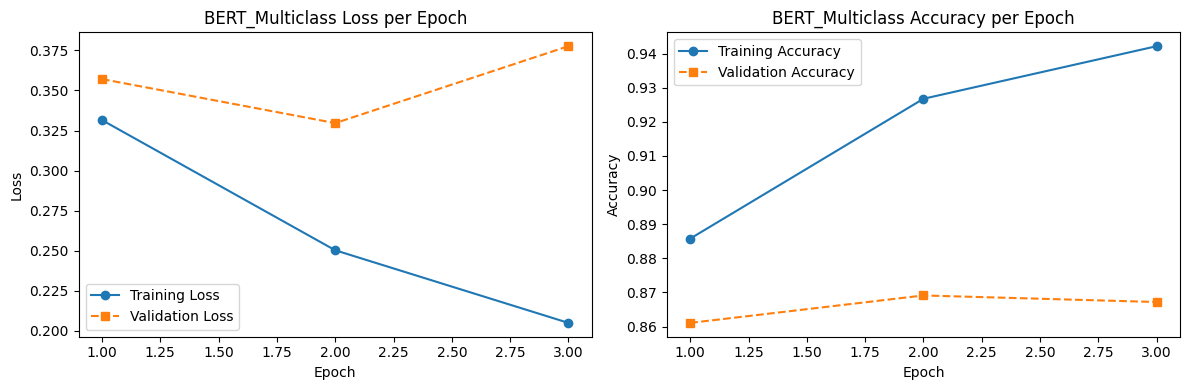

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20/BERT_Multiclass_Learning_Curves_By_Epoch.png


In [14]:


# Reproducibility
SEED = 42
set_seed(SEED)
os.environ["WANDB_DISABLED"] = "true"

# Load data
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

# Pick transformer text column automatically
if "text_trf" in train_df.columns:
    TEXT_COL = "text_trf"
elif "tweet_text" in train_df.columns:
    TEXT_COL = "tweet_text"
else:
    # fallback if you used another name
    TEXT_COL = train_df.columns[0]

for df in (train_df, val_df, test_df):
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    df["label"]  = df["label"].astype(int)

y_val  = val_df["label"].values
y_test = test_df["label"].values

# Class names
if os.path.exists(ID2LABEL_PATH):
    id2label = json.load(open(ID2LABEL_PATH))
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    K = len(sorted(train_df["label"].unique()))
    label_names = [f"class_{i}" for i in range(K)]

K = len(label_names)
print("TEXT_COL:", TEXT_COL)
print("K:", K, "| label_names:", label_names)
print("Sizes -> Train/Val/Test:", len(train_df), len(val_df), len(test_df))

# HF Datasets
train_ds = Dataset.from_pandas(train_df[[TEXT_COL, "label"]].rename(columns={TEXT_COL: "text"}).reset_index(drop=True))
val_ds   = Dataset.from_pandas(val_df[[TEXT_COL, "label"]].rename(columns={TEXT_COL: "text"}).reset_index(drop=True))
test_ds  = Dataset.from_pandas(test_df[[TEXT_COL, "label"]].rename(columns={TEXT_COL: "text"}).reset_index(drop=True))

# Tokenizer
MODEL_NAME = "bert-base-uncased"   # you asked for BERT
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

MAX_LEN = 128
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

train_ds = train_ds.map(tokenize, batched=True, remove_columns=["text"])
val_ds   = val_ds.map(tokenize, batched=True, remove_columns=["text"])
test_ds  = test_ds.map(tokenize, batched=True, remove_columns=["text"])

collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=K
)

# Metrics (macro + AUC OvR)
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    preds = np.argmax(probs, axis=1)

    acc = accuracy_score(labels, preds)
    p_macro = precision_score(labels, preds, average="macro", zero_division=0)
    r_macro = recall_score(labels, preds, average="macro", zero_division=0)
    f_macro = f1_score(labels, preds, average="macro", zero_division=0)

    p_w = precision_score(labels, preds, average="weighted", zero_division=0)
    r_w = recall_score(labels, preds, average="weighted", zero_division=0)
    f_w = f1_score(labels, preds, average="weighted", zero_division=0)

    # multiclass AUC OvR
    try:
        y_bin = label_binarize(labels, classes=list(range(K)))
        auc_macro = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except Exception:
        auc_macro = float("nan")

    return {
        "accuracy": acc,
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f_macro,
        "roc_auc_macro_ovr": auc_macro,
        "precision_weighted": p_w,
        "recall_weighted": r_w,
        "f1_weighted": f_w
    }

class TrainAccuracyCallback(TrainerCallback):
    def __init__(self, trainer):
        super().__init__()
        self.trainer = trainer

    def on_epoch_end(self, args, state, control, **kwargs):
        train_preds = self.trainer.predict(self.trainer.train_dataset)
        logits = train_preds.predictions
        labels = train_preds.label_ids

        preds = logits.argmax(-1)
        acc = accuracy_score(labels, preds)

        state.log_history.append({
            "epoch": state.epoch,
            "train_accuracy": acc
        })


def plot_bert_curves_by_epoch(trainer, results_dir, model_name="BERT_Multiclass"):
    logs = trainer.state.log_history

    #  epoch-level train loss
    train_loss_by_epoch = defaultdict(list)
    train_acc_by_epoch = defaultdict(list)

    for log in logs:
        # HF logs training loss in steps; aggregate by epoch
        if "loss" in log and "epoch" in log and "eval_loss" not in log:
            # Ceil or round can work; using int(round(...)) keeps alignment with eval epochs
            epoch_num = int(round(log["epoch"]))
            train_loss_by_epoch[epoch_num].append(log["loss"])
        if "train_accuracy" in log and "epoch" in log and "eval_loss" not in log:
            epoch_num = int(round(log["epoch"]))
            train_acc_by_epoch[epoch_num].append(log["train_accuracy"])

    train_epochs = sorted(train_loss_by_epoch.keys())
    train_loss_epoch = [np.mean(train_loss_by_epoch[e]) for e in train_epochs]

    #  epoch-level validation metrics
    val_loss_epoch = []
    val_acc_epoch = []
    eval_epochs = []

    for log in logs:
        if "eval_loss" in log and "epoch" in log:
            eval_epochs.append(int(round(log["epoch"])))
            val_loss_epoch.append(log["eval_loss"])
            # Trainer prefixes your metric keys with 'eval_'
            val_acc_epoch.append(log.get("eval_accuracy", None))

    if not eval_epochs:
        print("No evaluation logs found. Did you set evaluation_strategy='epoch'?")
        return

    # Align epochs so x-axes match between train and eval
    train_loss_aligned = [np.mean(train_loss_by_epoch[e]) if e in train_loss_by_epoch else np.nan for e in eval_epochs]
    train_acc_aligned = [np.mean(train_acc_by_epoch[e]) if e in train_acc_by_epoch else np.nan for e in eval_epochs]

    # Plot Loss + Accuracy
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # Loss subplot
    ax[0].plot(eval_epochs, train_loss_aligned, marker="o", label="Training Loss")
    ax[0].plot(eval_epochs, val_loss_epoch, marker="s", linestyle="--", label="Validation Loss")
    ax[0].set_title(f"{model_name} Loss per Epoch")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    # Accuracy subplot
    if any(~np.isnan(v) for v in val_acc_epoch) or any(~np.isnan(v) for v in train_acc_aligned):
        # Replace None with np.nan to avoid plotting errors
        val_acc_plot = [v if v is not None else np.nan for v in val_acc_epoch]
        ax[1].plot(eval_epochs, train_acc_aligned, marker="o", label="Training Accuracy")
        ax[1].plot(eval_epochs, val_acc_plot, marker="s", linestyle="--", label="Validation Accuracy")
        ax[1].set_title(f"{model_name} Accuracy per Epoch")
        ax[1].set_xlabel("Epoch")
        ax[1].set_ylabel("Accuracy")
        ax[1].legend()
    else:
        ax[1].axis("off")
        ax[1].text(0.5, 0.5, "No accuracy logs found", ha="center", va="center")

    plt.tight_layout()

    save_path = os.path.join(RESULTS_DIR, f"{model_name}_Learning_Curves_By_Epoch.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", save_path)


# TrainingArguments
training_args = TrainingArguments(
    output_dir=str(MODEL_DIRS["BERT"] / "bert_multiclass_output"),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_accuracy",
    greater_is_better=True,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none"
)


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(2)]
)

trainer.add_callback(TrainAccuracyCallback(trainer=trainer))

# Train
print("Starting BERT training...")
trainer.train()
print("BERT training complete.")

plot_bert_curves_by_epoch(trainer, RESULTS_DIR, model_name="BERT_Multiclass")

In [15]:
 # Predict VAL + TEST probabilities and save .npy
val_out = trainer.predict(val_ds)
test_out = trainer.predict(test_ds)
p_val = torch.softmax(torch.tensor(val_out.predictions), dim=1).numpy()
p_test = torch.softmax(torch.tensor(test_out.predictions), dim=1).numpy()
np.save(os.path.join(RESULTS_DIR, "val_probs_bert.npy"), p_val)
np.save(os.path.join(RESULTS_DIR, "test_probs_bert.npy"), p_test)
np.save(os.path.join(RESULTS_DIR, "val_labels.npy"), y_val)
np.save(os.path.join(RESULTS_DIR, "test_labels.npy"), y_test)
print("Saved probs/labels (.npy) to:", RESULTS_DIR)


# Final TEST metrics (macro + AUC OvR)
y_pred = np.argmax(p_test, axis=1)
acc = accuracy_score(y_test, y_pred)
p_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
r_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
p_w = precision_score(y_test, y_pred, average="weighted", zero_division=0)
r_w = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f_w = f1_score(y_test, y_pred, average="weighted", zero_division=0)
y_test_bin = label_binarize(y_test, classes=list(range(K)))
auc_macro = roc_auc_score(y_test_bin, p_test, average="macro", multi_class="ovr")

print("\nFINAL TEST METRICS (BERT multiclass):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {p_macro:.4f}")
print(f"Recall (Macro)      : {r_macro:.4f}")
print(f"F1 (Macro)          : {f_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {auc_macro:.4f}")
print(f"Precision (Weighted): {p_w:.4f}")
print(f"Recall (Weighted)   : {r_w:.4f}")
print(f"F1 (Weighted)       : {f_w:.4f}")

# Save one-row result CSV
row = pd.DataFrame([{
    "Model": "BERT-base-uncased",
    "Accuracy": acc,
    "Precision (Macro)": p_macro,
    "Recall (Macro)": r_macro,
    "F1 (Macro)": f_macro,
    "ROC-AUC (Macro OvR)": auc_macro,
    "Precision (Weighted)": p_w,
    "Recall (Weighted)": r_w,
    "F1 (Weighted)": f_w
}])
csv_path = os.path.join(RESULTS_DIR, "BERT_multiclass_performance.csv")
row.to_csv(csv_path, index=False)
print("Saved:", csv_path)

Saved probs/labels (.npy) to: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20

FINAL TEST METRICS (BERT multiclass):
Accuracy            : 0.8705
Precision (Macro)   : 0.8705
Recall (Macro)      : 0.8700
F1 (Macro)          : 0.8698
ROC-AUC (Macro OvR) : 0.9793
Precision (Weighted): 0.8712
Recall (Weighted)   : 0.8705
F1 (Weighted)       : 0.8705
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20/BERT_multiclass_performance.csv


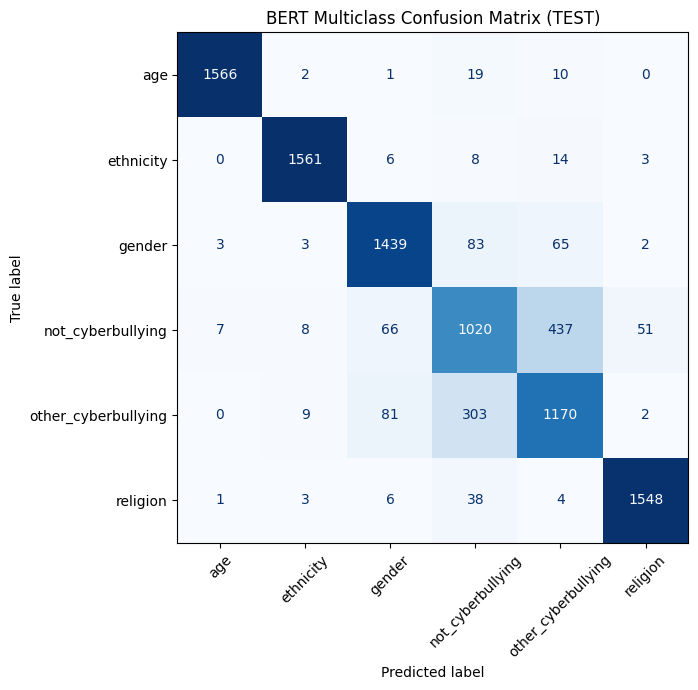

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20/CM_BERT_Multiclass_TEST.png


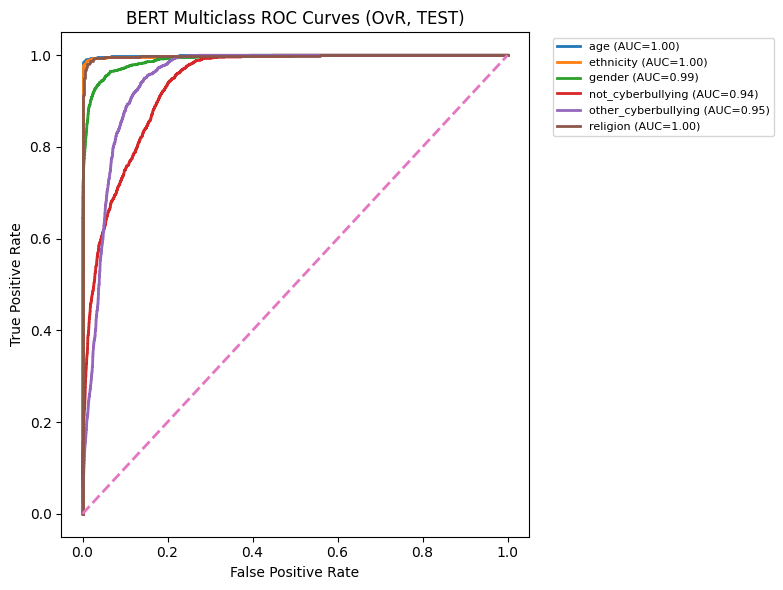

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20/ROC_BERT_Multiclass_OVR_TEST.png


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20/bert_multiclass_model

All BERT multiclass outputs saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20


In [16]:
# Confusion matrix (SAVE)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("BERT Multiclass Confusion Matrix (TEST)")
plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "CM_BERT_Multiclass_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)

# ROC curves OvR (SAVE)
plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], p_test[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("BERT Multiclass ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
roc_path = os.path.join(RESULTS_DIR, "ROC_BERT_Multiclass_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)

# Save model
model_path = os.path.join(RESULTS_DIR, "bert_multiclass_model")
trainer.save_model(model_path)
tokenizer.save_pretrained(model_path)
print("Saved model to:", model_path)

print("\nAll BERT multiclass outputs saved in:", RESULTS_DIR)

## RoBERTa




In [20]:
import os, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    set_seed
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# PATHS
DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
TRAIN_PATH = os.path.join(DATA_DIR, "train_80_MASTER_ALLMODELS.csv")
VAL_PATH   = os.path.join(DATA_DIR, "val_from_train_MASTER_ALLMODELS.csv")
TEST_PATH  = os.path.join(DATA_DIR, "test_20_MASTER_ALLMODELS.csv")
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")  # optional but recommended

RESULTS_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Reproducibility
SEED = 42
set_seed(SEED)
os.environ["WANDB_DISABLED"] = "true" # Disable WANDB for simplicity

# Load data
train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

# Pick transformer text column automatically
if "text_trf" in train_df.columns:
    TEXT_COL = "text_trf"
elif "tweet_text" in train_df.columns:
    TEXT_COL = "tweet_text"
else:
    # fallback if you used another name or column type
    TEXT_COL = train_df.columns[0] # assuming first column is text if others are not found

for df in (train_df, val_df, test_df):
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    df["label"]  = df["label"].astype(int)

y_val  = val_df["label"].values
y_test = test_df["label"].values

# Class names
if os.path.exists(ID2LABEL_PATH):
    with open(ID2LABEL_PATH, "r") as f:
        id2label = json.load(f)
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    K = len(sorted(train_df["label"].unique()))
    label_names = [f"class_{i}" for i in range(K)]

K = len(label_names)
print("TEXT_COL:", TEXT_COL)
print("K:", K, "| label_names:", label_names)
print("Sizes -> Train/Val/Test:", len(train_df), len(val_df), len(test_df))

# HF Datasets
train_ds = Dataset.from_pandas(train_df[[TEXT_COL, "label"]].rename(columns={TEXT_COL: "text"}).reset_index(drop=True))
val_ds   = Dataset.from_pandas(val_df[[TEXT_COL, "label"]].rename(columns={TEXT_COL: "text"}).reset_index(drop=True))
test_ds  = Dataset.from_pandas(test_df[[TEXT_COL, "label"]].rename(columns={TEXT_COL: "text"}).reset_index(drop=True))

# Tokenizer
MODEL_NAME = "roberta-base"   # Specify RoBERTa base model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

MAX_LEN = 128 # Define max sequence length
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

train_ds = train_ds.map(tokenize, batched=True, remove_columns=["text"])
val_ds   = val_ds.map(tokenize, batched=True, remove_columns=["text"])
test_ds  = test_ds.map(tokenize, batched=True, remove_columns=["text"])

collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("RoBERTa data setup complete.")

TEXT_COL: text_trf
K: 6 | label_names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Sizes -> Train/Val/Test: 32430 5723 9539


Map:   0%|          | 0/32430 [00:00<?, ? examples/s]

Map:   0%|          | 0/5723 [00:00<?, ? examples/s]

Map:   0%|          | 0/9539 [00:00<?, ? examples/s]

RoBERTa data setup complete.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting RoBERTa training...


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,Roc Auc Macro Ovr,Precision Weighted,Recall Weighted,F1 Weighted
1,0.339994,0.347167,0.867028,0.869693,0.866655,0.863615,0.978378,0.870469,0.867028,0.864218
2,0.279886,0.324120,0.879259,0.881339,0.878907,0.876800,0.980932,0.882057,0.879259,0.877357
3,0.206724,0.340192,0.878560,0.878303,0.878151,0.875629,0.981198,0.878974,0.878560,0.876183


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RoBERTa training complete.


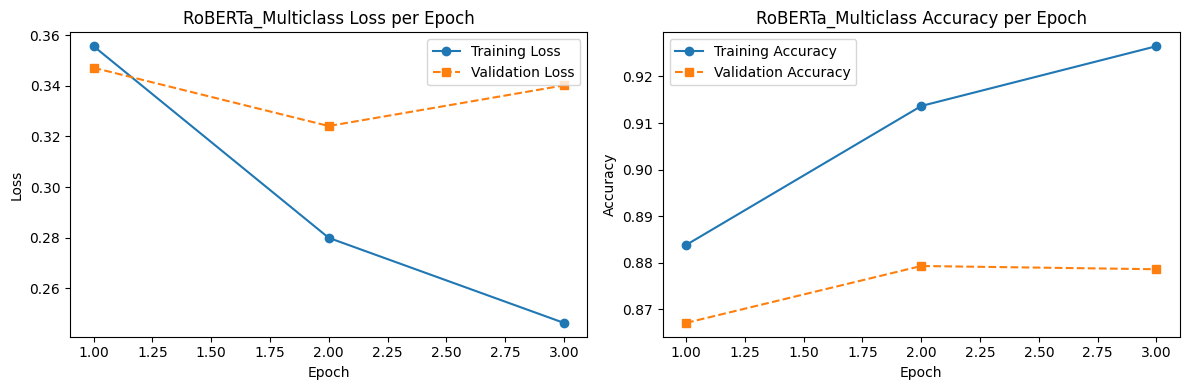

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20/RoBERTa_Multiclass_Learning_Curves.png


In [21]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer, EarlyStoppingCallback, TrainerCallback
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np
import torch
import os
import matplotlib.pyplot as plt
from collections import defaultdict

# Model initialization
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=K
)

# Metrics (macro + AUC OvR)
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    preds = np.argmax(probs, axis=1)

    acc = accuracy_score(labels, preds)
    p_macro = precision_score(labels, preds, average="macro", zero_division=0)
    r_macro = recall_score(labels, preds, average="macro", zero_division=0)
    f_macro = f1_score(labels, preds, average="macro", zero_division=0)

    p_w = precision_score(labels, preds, average="weighted", zero_division=0)
    r_w = recall_score(labels, preds, average="weighted", zero_division=0)
    f_w = f1_score(labels, preds, average="weighted", zero_division=0)

    # multiclass AUC OvR
    try:
        y_bin = label_binarize(labels, classes=list(range(K)))
        auc_macro = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except Exception:
        auc_macro = float("nan")

    return {
        "accuracy": acc,
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f_macro,
        "roc_auc_macro_ovr": auc_macro,
        "precision_weighted": p_w,
        "recall_weighted": r_w,
        "f1_weighted": f_w
    }

class TrainAccuracyCallback(TrainerCallback):
    def __init__(self, trainer):
        super().__init__()
        self.trainer = trainer

    def on_epoch_end(self, args, state, control, **kwargs):
        train_preds = self.trainer.predict(self.trainer.train_dataset)
        logits = train_preds.predictions
        labels = train_preds.label_ids

        preds = logits.argmax(-1)
        acc = accuracy_score(labels, preds)

        state.log_history.append({
            "epoch": state.epoch,
            "train_accuracy": acc
        })


# Plotting Learning Curves
def plot_roberta_curves_by_epoch(trainer, results_dir, model_name="RoBERTa_Multiclass"):
    logs = trainer.state.log_history

    train_loss_by_epoch = defaultdict(list)
    train_acc_by_epoch = defaultdict(list)
    for log in logs:
        if "loss" in log and "epoch" in log and "eval_loss" not in log:
            epoch_num = int(round(log["epoch"])) # Use round for epoch alignment
            train_loss_by_epoch[epoch_num].append(log["loss"])
        # Look for 'train_accuracy' logged by our custom callback
        if "train_accuracy" in log and "epoch" in log and "eval_loss" not in log:
            epoch_num = int(round(log["epoch"]))
            train_acc_by_epoch[epoch_num].append(log["train_accuracy"])

    train_epochs = sorted(train_loss_by_epoch.keys())
    train_loss_epoch = [np.mean(train_loss_by_epoch[e]) for e in train_epochs]

    # Using eval_epochs to align all curves
    eval_epochs = sorted(list(set([int(round(l["epoch"])) for l in logs if "eval_loss" in l and "epoch" in l]))) # Get actual eval epochs

    train_loss_aligned = [np.mean(train_loss_by_epoch[e]) if e in train_loss_by_epoch else np.nan for e in eval_epochs]
    train_acc_aligned = [np.mean(train_acc_by_epoch[e]) if e in train_acc_by_epoch else np.nan for e in eval_epochs]

    val_loss_epoch = []
    val_acc_epoch = []

    for log in logs:
        if "eval_loss" in log and "epoch" in log:
            val_loss_epoch.append(log["eval_loss"])
            val_acc_epoch.append(log.get("eval_accuracy", None))

    if not eval_epochs:
        print("No evaluation logs found. Did you set evaluation_strategy='epoch'?")
        return

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # Loss subplot
    ax[0].plot(eval_epochs, train_loss_aligned, marker="o", label="Training Loss")
    ax[0].plot(eval_epochs, val_loss_epoch, marker="s", linestyle="--", label="Validation Loss")
    ax[0].set_title(f"{model_name} Loss per Epoch")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    # Accuracy subplot
    if any(v is not None for v in val_acc_epoch) or any(~np.isnan(v) for v in train_acc_aligned):
        val_acc_plot = [v if v is not None else np.nan for v in val_acc_epoch]
        ax[1].plot(eval_epochs, train_acc_aligned, marker="o", label="Training Accuracy")
        ax[1].plot(eval_epochs, val_acc_plot, marker="s", linestyle="--", label="Validation Accuracy")
        ax[1].set_title(f"{model_name} Accuracy per Epoch")
        ax[1].set_xlabel("Epoch")
        ax[1].set_ylabel("Accuracy")
        ax[1].legend()
    else:
        ax[1].axis("off")
        ax[1].text(0.5, 0.5, "No accuracy logs found", ha="center", va="center")

    plt.tight_layout()

    save_path = os.path.join(results_dir, f"{model_name}_Learning_Curves.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close() # Close plot to prevent display issues in some environments
    print("Saved:", save_path)

# TrainingArguments
training_args = TrainingArguments(
    output_dir=str(MODEL_DIRS["ROBERTA"] / "roberta_multiclass_output"),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_accuracy",
    greater_is_better=True,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)] # Removed TrainAccuracyCallback from here
)
# Set trainer reference after instantiation
trainer.add_callback(TrainAccuracyCallback(trainer=trainer))

# Train
print("Starting RoBERTa training...")
trainer.train()
print("RoBERTa training complete.")

plot_roberta_curves_by_epoch(trainer, RESULTS_DIR, model_name="RoBERTa_Multiclass")


**Reasoning**:
The previous code block successfully trained the RoBERTa model and plotted the learning curves. The next steps involve predicting probabilities, saving them, evaluating the model's performance on the test set with various metrics, visualizing these metrics through confusion matrices and ROC curves, saving the performance metrics to a CSV, and finally saving the trained model and tokenizer.



Saved probs/labels (.npy) to: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20

FINAL TEST METRICS (RoBERTa multiclass):
Accuracy            : 0.8760
Precision (Macro)   : 0.8774
Recall (Macro)      : 0.8756
F1 (Macro)          : 0.8734
ROC-AUC (Macro OvR) : 0.9803
Precision (Weighted): 0.8781
Recall (Weighted)   : 0.8760
F1 (Weighted)       : 0.8740
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20/RoBERTa_multiclass_performance.csv


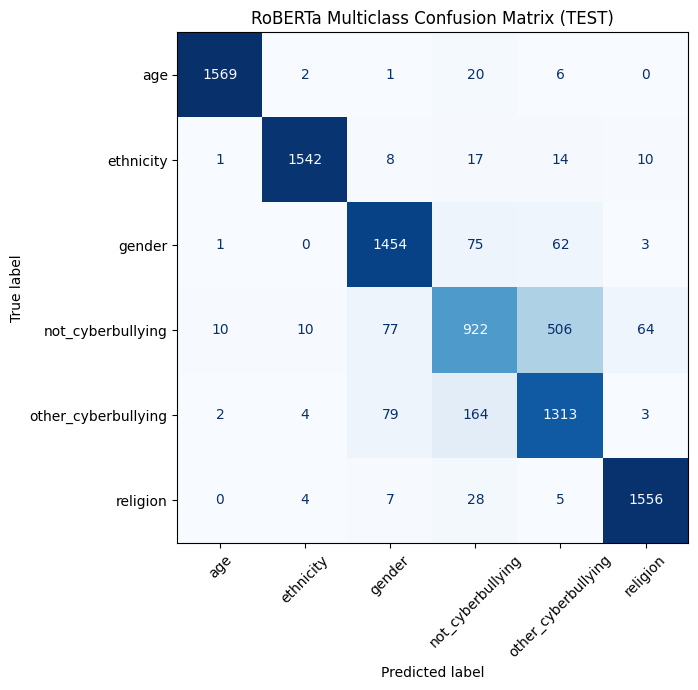

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20/CM_RoBERTa_Multiclass_TEST.png


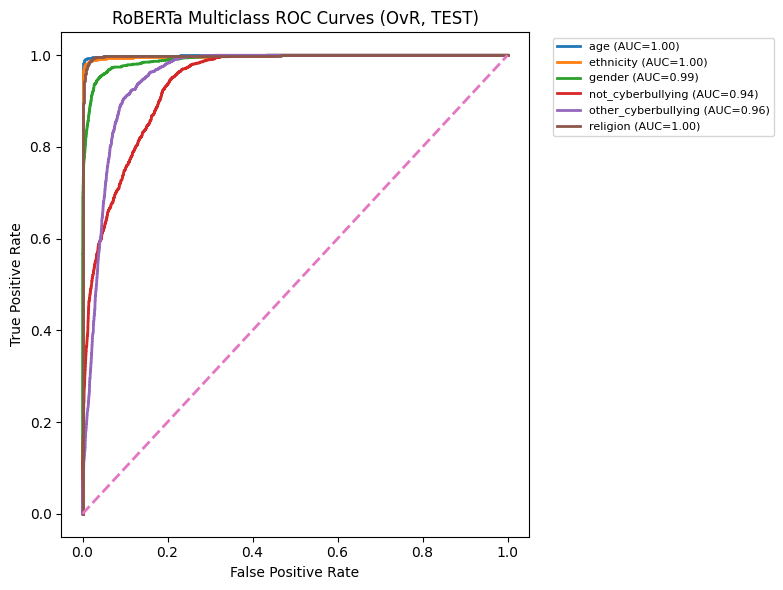

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20/ROC_RoBERTa_Multiclass_OVR_TEST.png


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20/roberta_multiclass_model

All RoBERTa multiclass outputs saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20


In [22]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# Predict VAL + TEST probabilities and save .npy
val_out  = trainer.predict(val_ds)
test_out = trainer.predict(test_ds)

p_val  = torch.softmax(torch.tensor(val_out.predictions),  dim=1).numpy()
p_test = torch.softmax(torch.tensor(test_out.predictions), dim=1).numpy()

# The y_val and y_test were already loaded and stored earlier.
np.save(os.path.join(RESULTS_DIR, "val_probs_roberta.npy"),  p_val)
np.save(os.path.join(RESULTS_DIR, "test_probs_roberta.npy"), p_test)
np.save(os.path.join(RESULTS_DIR, "val_labels.npy"), y_val)
np.save(os.path.join(RESULTS_DIR, "test_labels.npy"), y_test)
print("Saved probs/labels (.npy) to:", RESULTS_DIR)

# Final TEST metrics (macro + AUC OvR)
y_pred = np.argmax(p_test, axis=1)

acc = accuracy_score(y_test, y_pred)
p_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
r_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

p_w = precision_score(y_test, y_pred, average="weighted", zero_division=0)
r_w = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f_w = f1_score(y_test, y_pred, average="weighted", zero_division=0)

y_test_bin = label_binarize(y_test, classes=list(range(K)))
auc_macro = roc_auc_score(y_test_bin, p_test, average="macro", multi_class="ovr")

print("\nFINAL TEST METRICS (RoBERTa multiclass):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {p_macro:.4f}")
print(f"Recall (Macro)      : {r_macro:.4f}")
print(f"F1 (Macro)          : {f_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {auc_macro:.4f}")
print(f"Precision (Weighted): {p_w:.4f}")
print(f"Recall (Weighted)   : {r_w:.4f}")
print(f"F1 (Weighted)       : {f_w:.4f}")

# Save one-row result CSV
row = pd.DataFrame([{
    "Model": "RoBERTa-base",
    "Accuracy": acc,
    "Precision (Macro)": p_macro,
    "Recall (Macro)": r_macro,
    "F1 (Macro)": f_macro,
    "ROC-AUC (Macro OvR)": auc_macro,
    "Precision (Weighted)": p_w,
    "Recall (Weighted)": r_w,
    "F1 (Weighted)": f_w
}])
csv_path = os.path.join(RESULTS_DIR, "RoBERTa_multiclass_performance.csv")
row.to_csv(csv_path, index=False)
print("Saved:", csv_path)

# Confusion matrix (SAVE)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("RoBERTa Multiclass Confusion Matrix (TEST)")
plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "CM_RoBERTa_Multiclass_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)

# ROC curves OvR (SAVE)
plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], p_test[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("RoBERTa Multiclass ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
roc_path = os.path.join(RESULTS_DIR, "ROC_RoBERTa_Multiclass_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)

# Save model
model_path = os.path.join(RESULTS_DIR, "roberta_multiclass_model")
trainer.save_model(model_path)
tokenizer.save_pretrained(model_path)
print("Saved model to:", model_path)

print("\nAll RoBERTa multiclass outputs saved in:", RESULTS_DIR)


#Ensemble bert cnn

Classes: 6
Label names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
bert_test_probs shape      : (9539, 6)
cnn_glove_test_probs shape : (9539, 6)
bert_test_labels shape     : (9539,)
cnn_glove_test_labels shape: (9539,)

FINAL TEST METRICS (Soft Voting Ensemble BERT + CNN-GloVe):
Accuracy            : 0.8716
Precision (Macro)   : 0.8718
Recall (Macro)      : 0.8711
F1 (Macro)          : 0.8705
ROC-AUC (Macro OvR) : 0.9792
Precision (Weighted): 0.8725
Recall (Weighted)   : 0.8716
F1 (Weighted)       : 0.8711
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_BERT_CNN_GloVe/Soft_Voting_Ensemble_BERT_CNN_GloVe_multiclass_performance.csv

Classification Report:

                     precision    recall  f1-score   support

                age     0.9924    0.9806    0.9865      1598
          ethnicity     0.9836    0.9793    0.9814      1592
             gender     0.8993    0.8959    0.8976      1595
  

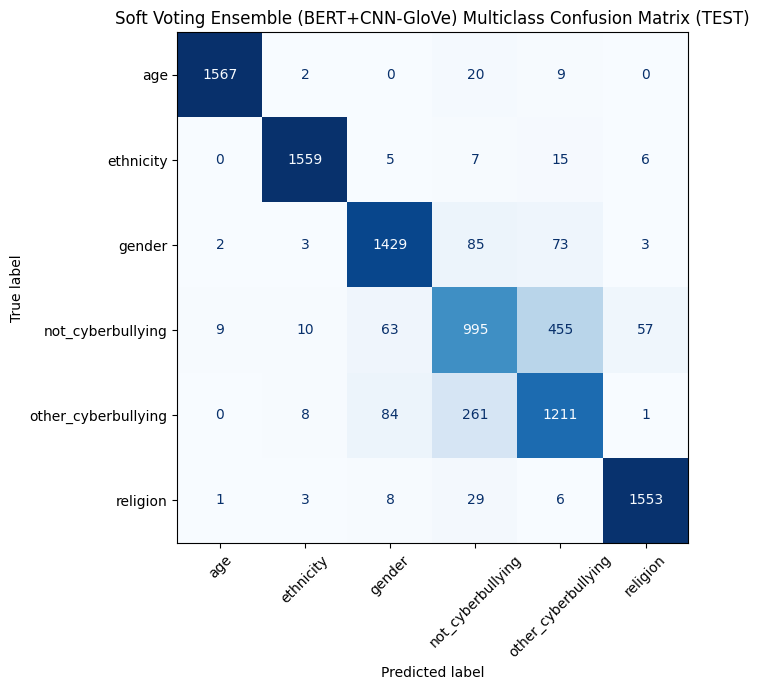

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_BERT_CNN_GloVe/CM_Soft_Voting_Ensemble_BERT_CNN_GloVe_Multiclass_TEST.png


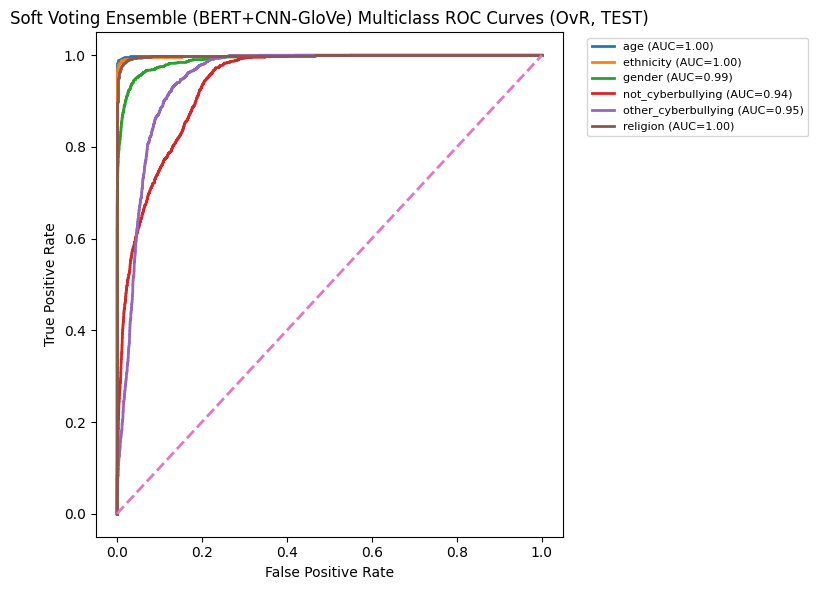

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_BERT_CNN_GloVe/ROC_Soft_Voting_Ensemble_BERT_CNN_GloVe_Multiclass_OVR_TEST.png
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_BERT_CNN_GloVe/test_predictions_soft_voting_bert_cnn_glove.csv

All Soft Voting Ensemble (BERT+CNN-GloVe) outputs saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_BERT_CNN_GloVe


In [19]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    classification_report
)
from sklearn.preprocessing import label_binarize

# 1. PATHS
DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

BERT_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/BERT_Multiclass_80_20"
CNN_GLOVE_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20"

RESULTS_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_BERT_CNN_GloVe"
os.makedirs(RESULTS_DIR, exist_ok=True)

# 2. LOAD LABEL NAMES
if os.path.exists(ID2LABEL_PATH):
    with open(ID2LABEL_PATH, "r", encoding="utf-8") as f:
        id2label = json.load(f)
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    raise FileNotFoundError(f"id2label.json not found at: {ID2LABEL_PATH}")

K = len(label_names)

print("Classes:", K)
print("Label names:", label_names)

# 3. LOAD SAVED PROBABILITIES AND LABELS
bert_test_probs = np.load(os.path.join(BERT_DIR, "test_probs_bert.npy"))
bert_test_labels = np.load(os.path.join(BERT_DIR, "test_labels.npy"))

cnn_glove_test_probs = np.load(os.path.join(CNN_GLOVE_DIR, "test_probs_cnn_glove.npy"))
cnn_glove_test_labels = np.load(os.path.join(CNN_GLOVE_DIR, "test_labels.npy"))

print("bert_test_probs shape      :", bert_test_probs.shape)
print("cnn_glove_test_probs shape :", cnn_glove_test_probs.shape)
print("bert_test_labels shape     :", bert_test_labels.shape)
print("cnn_glove_test_labels shape:", cnn_glove_test_labels.shape)

# 4. CHECK LABEL ALIGNMENT
if not np.array_equal(bert_test_labels, cnn_glove_test_labels):
    raise ValueError("BERT and CNN-GloVe test labels do not match. Check your saved files.")

test_labels = bert_test_labels

# 5. SOFT VOTING ENSEMBLE
# Equal soft voting
ensemble_test_probs = 0.6 * bert_test_probs + 0.4 * cnn_glove_test_probs

# Optional weighted soft voting
# Since BERT is usually stronger than CNN-GloVe, you can also try:
# ensemble_test_probs = 0.6 * bert_test_probs + 0.4 * cnn_glove_test_probs

y_pred_ensemble = np.argmax(ensemble_test_probs, axis=1)

# 6. METRICS
acc = accuracy_score(test_labels, y_pred_ensemble)

p_macro = precision_score(test_labels, y_pred_ensemble, average="macro", zero_division=0)
r_macro = recall_score(test_labels, y_pred_ensemble, average="macro", zero_division=0)
f_macro = f1_score(test_labels, y_pred_ensemble, average="macro", zero_division=0)

p_w = precision_score(test_labels, y_pred_ensemble, average="weighted", zero_division=0)
r_w = recall_score(test_labels, y_pred_ensemble, average="weighted", zero_division=0)
f_w = f1_score(test_labels, y_pred_ensemble, average="weighted", zero_division=0)

y_test_bin = label_binarize(test_labels, classes=list(range(K)))
auc_macro = roc_auc_score(
    y_test_bin,
    ensemble_test_probs,
    average="macro",
    multi_class="ovr"
)

print("\nFINAL TEST METRICS (Soft Voting Ensemble BERT + CNN-GloVe):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {p_macro:.4f}")
print(f"Recall (Macro)      : {r_macro:.4f}")
print(f"F1 (Macro)          : {f_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {auc_macro:.4f}")
print(f"Precision (Weighted): {p_w:.4f}")
print(f"Recall (Weighted)   : {r_w:.4f}")
print(f"F1 (Weighted)       : {f_w:.4f}")

# 7. SAVE PERFORMANCE CSV
row = pd.DataFrame([{
    "Model": "Soft Voting Ensemble (BERT+CNN_GloVe)",
    "Accuracy": acc,
    "Precision (Macro)": p_macro,
    "Recall (Macro)": r_macro,
    "F1 (Macro)": f_macro,
    "ROC-AUC (Macro OvR)": auc_macro,
    "Precision (Weighted)": p_w,
    "Recall (Weighted)": r_w,
    "F1 (Weighted)": f_w
}])

csv_path = os.path.join(RESULTS_DIR, "Soft_Voting_Ensemble_BERT_CNN_GloVe_multiclass_performance.csv")
row.to_csv(csv_path, index=False)
print("Saved:", csv_path)

# 8. CLASSIFICATION REPORT
report = classification_report(
    test_labels,
    y_pred_ensemble,
    target_names=label_names,
    digits=4,
    zero_division=0
)

print("\nClassification Report:\n")
print(report)

report_path = os.path.join(RESULTS_DIR, "classification_report_soft_voting_bert_cnn_glove.txt")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)
print("Saved:", report_path)

# 9. CONFUSION MATRIX
cm = confusion_matrix(test_labels, y_pred_ensemble)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("Soft Voting Ensemble (BERT+CNN-GloVe) Multiclass Confusion Matrix (TEST)")
plt.tight_layout()

cm_path = os.path.join(RESULTS_DIR, "CM_Soft_Voting_Ensemble_BERT_CNN_GloVe_Multiclass_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)

# 10. ROC CURVES
plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], ensemble_test_probs[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Soft Voting Ensemble (BERT+CNN-GloVe) Multiclass ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()

roc_path = os.path.join(RESULTS_DIR, "ROC_Soft_Voting_Ensemble_BERT_CNN_GloVe_Multiclass_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)

# 11. SAVE PREDICTIONS
pred_df = pd.DataFrame({
    "true_label_id": test_labels,
    "pred_label_id": y_pred_ensemble,
    "true_label_name": [label_names[i] for i in test_labels],
    "pred_label_name": [label_names[i] for i in y_pred_ensemble]
})

for i in range(K):
    pred_df[f"prob_class_{i}_{label_names[i]}"] = ensemble_test_probs[:, i]

pred_path = os.path.join(RESULTS_DIR, "test_predictions_soft_voting_bert_cnn_glove.csv")
pred_df.to_csv(pred_path, index=False)
print("Saved:", pred_path)

print("\nAll Soft Voting Ensemble (BERT+CNN-GloVe) outputs saved in:", RESULTS_DIR)

#Roberta_CNN Ensemble

Classes: 6
Label names: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
roberta_test_probs shape   : (9539, 6)
cnn_glove_test_probs shape : (9539, 6)
roberta_test_labels shape  : (9539,)
cnn_glove_test_labels shape: (9539,)

FINAL TEST METRICS (Soft Voting Ensemble RoBERTa + CNN-GloVe):
Accuracy            : 0.8759
Precision (Macro)   : 0.8780
Recall (Macro)      : 0.8755
F1 (Macro)          : 0.8732
ROC-AUC (Macro OvR) : 0.9797
Precision (Weighted): 0.8787
Recall (Weighted)   : 0.8759
F1 (Weighted)       : 0.8738
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe_multiclass_performance.csv

Classification Report:

                     precision    recall  f1-score   support

                age     0.9912    0.9819    0.9865      1598
          ethnicity     0.9847    0.9698    0.9772      1592
             gender     0.8919    0.9053    0.8986    

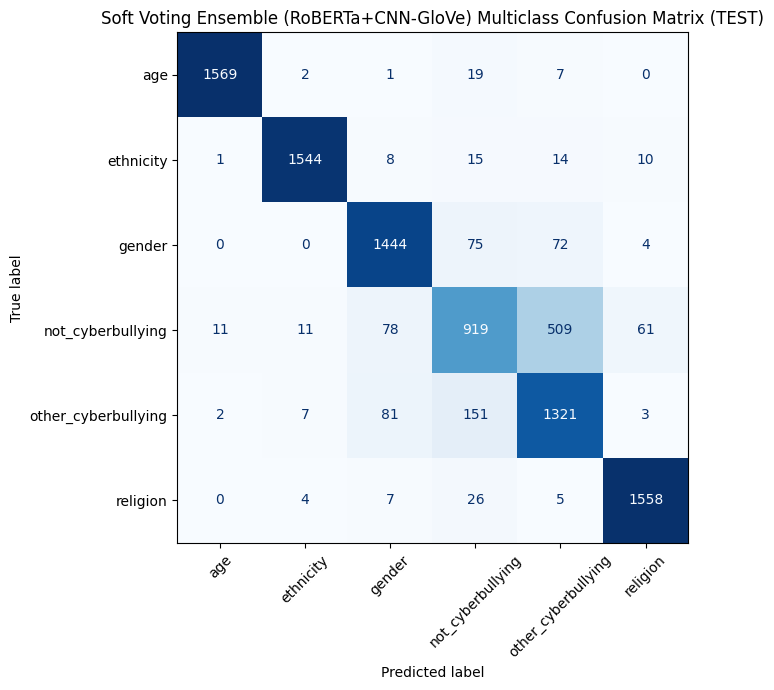

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe/CM_Soft_Voting_Ensemble_RoBERTa_CNN_GloVe_Multiclass_TEST.png


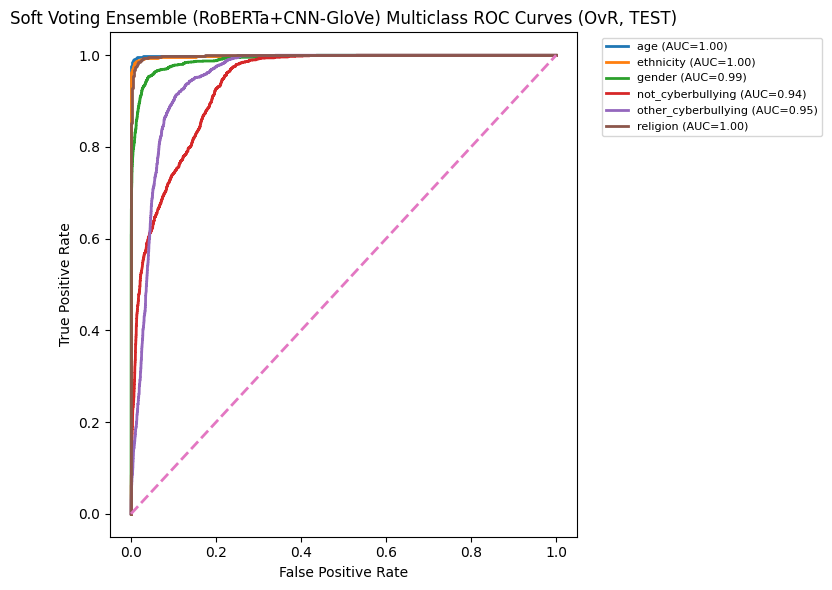

Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe/ROC_Soft_Voting_Ensemble_RoBERTa_CNN_GloVe_Multiclass_OVR_TEST.png
Saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe/test_predictions_soft_voting_roberta_cnn_glove.csv

All Soft Voting Ensemble (RoBERTa+CNN-GloVe) outputs saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe


In [23]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    classification_report
)
from sklearn.preprocessing import label_binarize

# PATHS
DATA_DIR = "/content/drive/MyDrive/Cyberbullying_Project/Datasets/English_dataset/multiclass_splits_80_20_MASTER_ALLMODELS"
ID2LABEL_PATH = os.path.join(DATA_DIR, "id2label.json")

ROBERTA_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/RoBERTa_Multiclass_80_20"
CNN_GLOVE_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/CNN_GloVe_Multiclass_80_20"

RESULTS_DIR = "/content/drive/MyDrive/multiclass-cyberbullying-detection/results/Soft_Voting_Ensemble_RoBERTa_CNN_GloVe"
os.makedirs(RESULTS_DIR, exist_ok=True)

# 2. LOAD LABEL NAMES
if os.path.exists(ID2LABEL_PATH):
    with open(ID2LABEL_PATH, "r", encoding="utf-8") as f:
        id2label = json.load(f)
    label_names = [id2label[str(i)] for i in range(len(id2label))]
else:
    raise FileNotFoundError(f"id2label.json not found at: {ID2LABEL_PATH}")

K = len(label_names)

print("Classes:", K)
print("Label names:", label_names)

# 3. LOAD SAVED PROBABILITIES AND LABELS
roberta_test_probs = np.load(os.path.join(ROBERTA_DIR, "test_probs_roberta.npy"))
roberta_test_labels = np.load(os.path.join(ROBERTA_DIR, "test_labels.npy"))

cnn_glove_test_probs = np.load(os.path.join(CNN_GLOVE_DIR, "test_probs_cnn_glove.npy"))
cnn_glove_test_labels = np.load(os.path.join(CNN_GLOVE_DIR, "test_labels.npy"))

print("roberta_test_probs shape   :", roberta_test_probs.shape)
print("cnn_glove_test_probs shape :", cnn_glove_test_probs.shape)
print("roberta_test_labels shape  :", roberta_test_labels.shape)
print("cnn_glove_test_labels shape:", cnn_glove_test_labels.shape)

# CHECK LABEL ALIGNMENT
if not np.array_equal(roberta_test_labels, cnn_glove_test_labels):
    raise ValueError("RoBERTa and CNN-GloVe test labels do not match. Check your saved files.")

test_labels = roberta_test_labels

# 5. SOFT VOTING ENSEMBLE
# Equal soft voting
ensemble_test_probs = 0.6 * roberta_test_probs + 0.4 * cnn_glove_test_probs


# ensemble_test_probs = 0.7 * roberta_test_probs + 0.3 * cnn_glove_test_probs
# ensemble_test_probs = 0.6 * roberta_test_probs + 0.4 * cnn_glove_test_probs

y_pred_ensemble = np.argmax(ensemble_test_probs, axis=1)

#  METRICS
acc = accuracy_score(test_labels, y_pred_ensemble)

p_macro = precision_score(test_labels, y_pred_ensemble, average="macro", zero_division=0)
r_macro = recall_score(test_labels, y_pred_ensemble, average="macro", zero_division=0)
f_macro = f1_score(test_labels, y_pred_ensemble, average="macro", zero_division=0)

p_w = precision_score(test_labels, y_pred_ensemble, average="weighted", zero_division=0)
r_w = recall_score(test_labels, y_pred_ensemble, average="weighted", zero_division=0)
f_w = f1_score(test_labels, y_pred_ensemble, average="weighted", zero_division=0)

y_test_bin = label_binarize(test_labels, classes=list(range(K)))
auc_macro = roc_auc_score(
    y_test_bin,
    ensemble_test_probs,
    average="macro",
    multi_class="ovr"
)

print("\nFINAL TEST METRICS (Soft Voting Ensemble RoBERTa + CNN-GloVe):")
print(f"Accuracy            : {acc:.4f}")
print(f"Precision (Macro)   : {p_macro:.4f}")
print(f"Recall (Macro)      : {r_macro:.4f}")
print(f"F1 (Macro)          : {f_macro:.4f}")
print(f"ROC-AUC (Macro OvR) : {auc_macro:.4f}")
print(f"Precision (Weighted): {p_w:.4f}")
print(f"Recall (Weighted)   : {r_w:.4f}")
print(f"F1 (Weighted)       : {f_w:.4f}")

# SAVE PERFORMANCE
row = pd.DataFrame([{
    "Model": "Soft Voting Ensemble (RoBERTa+CNN_GloVe)",
    "Accuracy": acc,
    "Precision (Macro)": p_macro,
    "Recall (Macro)": r_macro,
    "F1 (Macro)": f_macro,
    "ROC-AUC (Macro OvR)": auc_macro,
    "Precision (Weighted)": p_w,
    "Recall (Weighted)": r_w,
    "F1 (Weighted)": f_w
}])

csv_path = os.path.join(RESULTS_DIR, "Soft_Voting_Ensemble_RoBERTa_CNN_GloVe_multiclass_performance.csv")
row.to_csv(csv_path, index=False)
print("Saved:", csv_path)

# CLASSIFICATION REPORT
report = classification_report(
    test_labels,
    y_pred_ensemble,
    target_names=label_names,
    digits=4,
    zero_division=0
)

print("\nClassification Report:\n")
print(report)

report_path = os.path.join(RESULTS_DIR, "classification_report_soft_voting_roberta_cnn_glove.txt")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)
print("Saved:", report_path)

#  CONFUSION MATRIX
cm = confusion_matrix(test_labels, y_pred_ensemble)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False, values_format="d")
plt.title("Soft Voting Ensemble (RoBERTa+CNN-GloVe) Multiclass Confusion Matrix (TEST)")
plt.tight_layout()

cm_path = os.path.join(RESULTS_DIR, "CM_Soft_Voting_Ensemble_RoBERTa_CNN_GloVe_Multiclass_TEST.png")
plt.savefig(cm_path, dpi=300)
plt.show()
plt.close()
print("Saved:", cm_path)


# 10. ROC CURVES
plt.figure(figsize=(8, 6))
for c in range(K):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], ensemble_test_probs[:, c])
    roc_auc_c = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{label_names[c]} (AUC={roc_auc_c:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Soft Voting Ensemble (RoBERTa+CNN-GloVe) Multiclass ROC Curves (OvR, TEST)")
plt.legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()

roc_path = os.path.join(RESULTS_DIR, "ROC_Soft_Voting_Ensemble_RoBERTa_CNN_GloVe_Multiclass_OVR_TEST.png")
plt.savefig(roc_path, dpi=300)
plt.show()
plt.close()
print("Saved:", roc_path)

# SAVE PREDICTIONS
pred_df = pd.DataFrame({
    "true_label_id": test_labels,
    "pred_label_id": y_pred_ensemble,
    "true_label_name": [label_names[i] for i in test_labels],
    "pred_label_name": [label_names[i] for i in y_pred_ensemble]
})

for i in range(K):
    pred_df[f"prob_class_{i}_{label_names[i]}"] = ensemble_test_probs[:, i]

pred_path = os.path.join(RESULTS_DIR, "test_predictions_soft_voting_roberta_cnn_glove.csv")
pred_df.to_csv(pred_path, index=False)
print("Saved:", pred_path)

print("\nAll Soft Voting Ensemble (RoBERTa+CNN-GloVe) outputs saved in:", RESULTS_DIR)

In [24]:

import pandas as pd
from pathlib import Path

# Main project directories
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Model comparison results
comparison_data = [
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.8278,
        "Precision_Macro": 0.8316,
        "Recall_Macro": 0.8272,
        "F1_Macro": 0.8275,
        "ROC_AUC_Macro": None,
        "F1_Weighted": 0.8283
    },
    {
        "Model": "Calibrated LinearSVC",
        "Accuracy": 0.8225,
        "Precision_Macro": 0.8237,
        "Recall_Macro": 0.8218,
        "F1_Macro": 0.8215,
        "ROC_AUC_Macro": None,
        "F1_Weighted": 0.8224
    },
    {
        "Model": "CNN",
        "Accuracy": 0.8310,
        "Precision_Macro": 0.8326,
        "Recall_Macro": 0.8304,
        "F1_Macro": 0.8282,
        "ROC_AUC_Macro": 0.9682,
        "F1_Weighted": 0.8290
    },
    {
        "Model": "CNN + GloVe",
        "Accuracy": 0.8418,
        "Precision_Macro": 0.8477,
        "Recall_Macro": 0.8414,
        "F1_Macro": 0.8388,
        "ROC_AUC_Macro": 0.9723,
        "F1_Weighted": 0.8395
    },
    {
        "Model": "BiLSTM",
        "Accuracy": 0.8203,
        "Precision_Macro": 0.8286,
        "Recall_Macro": 0.8199,
        "F1_Macro": 0.8119,
        "ROC_AUC_Macro": 0.9639,
        "F1_Weighted": 0.8127
    },
    {
        "Model": "BiLSTM + GloVe",
        "Accuracy": 0.8251,
        "Precision_Macro": 0.8364,
        "Recall_Macro": 0.8249,
        "F1_Macro": 0.8189,
        "ROC_AUC_Macro": 0.9687,
        "F1_Weighted": 0.8196
    },
    {
        "Model": "BERT",
        "Accuracy": 0.8705,
        "Precision_Macro": 0.8705,
        "Recall_Macro": 0.8700,
        "F1_Macro": 0.8698,
        "ROC_AUC_Macro": 0.9793,
        "F1_Weighted": 0.8705
    },
    {
        "Model": "RoBERTa",
        "Accuracy": 0.8760,
        "Precision_Macro": 0.8774,
        "Recall_Macro": 0.8756,
        "F1_Macro": 0.8734,
        "ROC_AUC_Macro": 0.9803,
        "F1_Weighted": 0.8740
    },
    {
        "Model": "BERT + CNN-GloVe",
        "Accuracy": 0.8716,
        "Precision_Macro": 0.8718,
        "Recall_Macro": 0.8711,
        "F1_Macro": 0.8705,
        "ROC_AUC_Macro": 0.9792,
        "F1_Weighted": 0.8711
    },
    {
        "Model": "RoBERTa + CNN-GloVe",
        "Accuracy": 0.8759,
        "Precision_Macro": 0.8780,
        "Recall_Macro": 0.8755,
        "F1_Macro": 0.8732,
        "ROC_AUC_Macro": 0.9797,
        "F1_Weighted": 0.8738
    }
]

# Create DataFrame
comparison_df = pd.DataFrame(comparison_data)

comparison_df = comparison_df.sort_values(
    by="F1_Macro", ascending=False
).reset_index(drop=True)

# Save CSV
comparison_path = METRICS_DIR / "final_model_comparison.csv"

comparison_df.to_csv(comparison_path, index=False)

# Display results
display(comparison_df)

print("\nComparison file saved successfully:")
print(comparison_path)


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,ROC_AUC_Macro,F1_Weighted
0,RoBERTa,0.8760,0.8774,0.8756,0.8734,0.9803,0.8740
1,RoBERTa + CNN-GloVe,0.8759,0.8780,0.8755,0.8732,0.9797,0.8738
2,BERT + CNN-GloVe,0.8716,0.8718,0.8711,0.8705,0.9792,0.8711
3,BERT,0.8705,0.8705,0.8700,0.8698,0.9793,0.8705
4,CNN + GloVe,0.8418,0.8477,0.8414,0.8388,0.9723,0.8395
5,CNN,0.8310,0.8326,0.8304,0.8282,0.9682,0.8290
6,Logistic Regression,0.8278,0.8316,0.8272,0.8275,NaN,0.8283
7,Calibrated LinearSVC,0.8225,0.8237,0.8218,0.8215,NaN,0.8224
8,BiLSTM + GloVe,0.8251,0.8364,0.8249,0.8189,0.9687,0.8196
9,BiLSTM,0.8203,0.8286,0.8199,0.8119,0.9639,0.8127



Comparison file saved successfully:
/content/drive/MyDrive/multiclass-cyberbullying-detection/results/metrics/final_model_comparison.csv


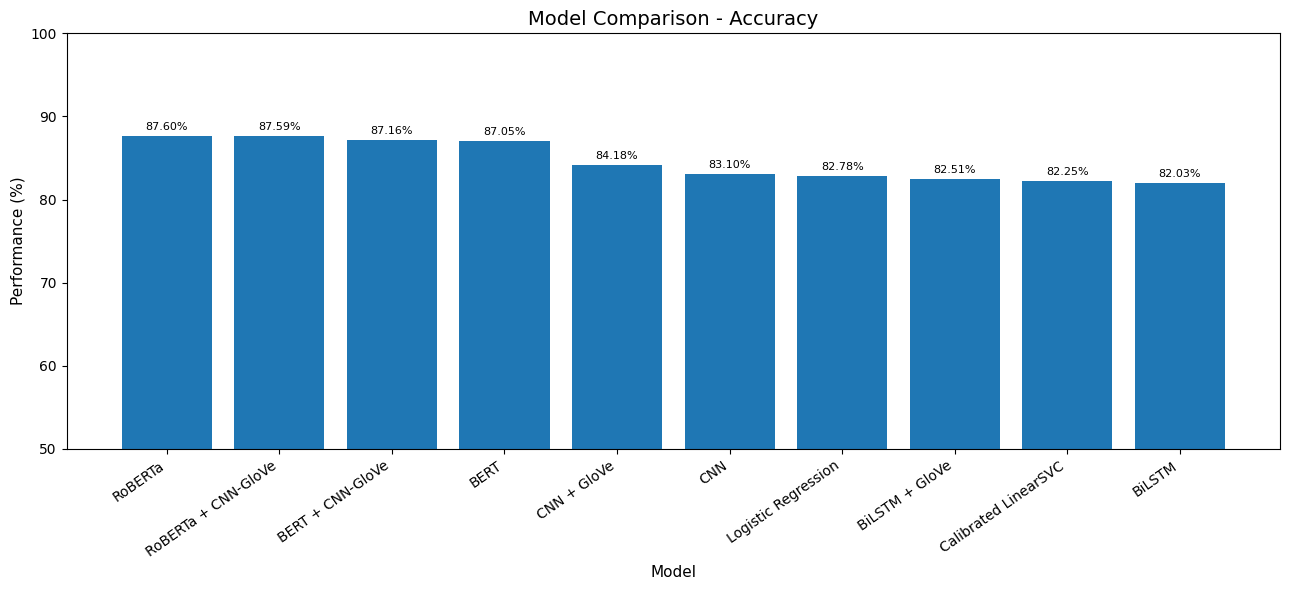

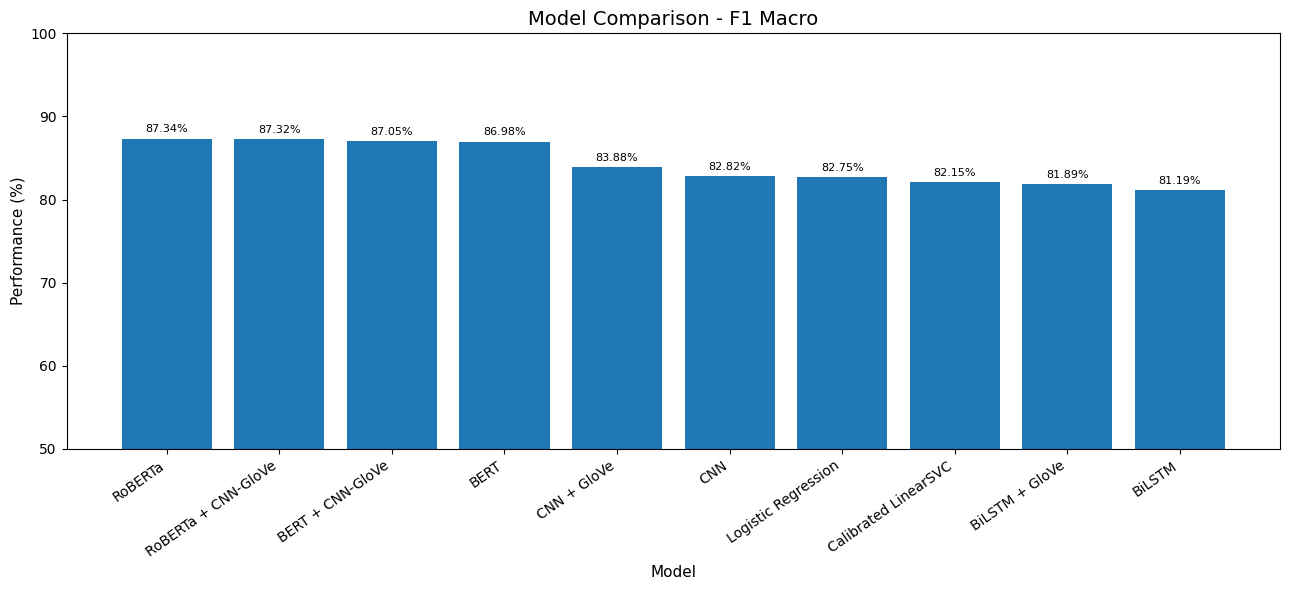

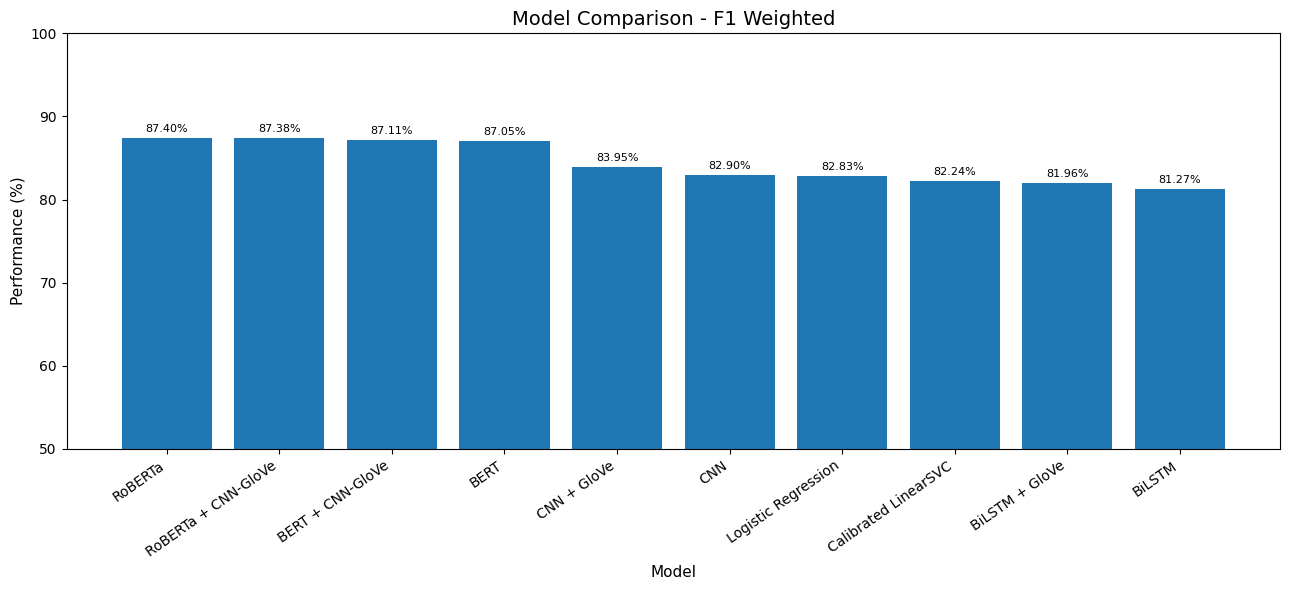

Updated vertical comparison charts saved in: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/figures


In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Define the paths
PROJECT_DIR = Path("/content/drive/MyDrive/multiclass-cyberbullying-detection")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
FIGURES_DIR = PROJECT_DIR / "results" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load saved comparison results
comparison_df = pd.read_csv(
    METRICS_DIR / "final_model_comparison.csv"
)

metrics = ["Accuracy", "F1_Macro", "F1_Weighted"]

plot_df = comparison_df.copy()

# Convert scores to percentages
for metric in metrics:
    plot_df[metric] = plot_df[metric] * 100

# Generate vertical bar charts
for metric in metrics:

    plot_data = plot_df.sort_values(
        metric, ascending=False
    )

    plt.figure(figsize=(13, 6))

    bars = plt.bar(
        plot_data["Model"],
        plot_data[metric]
    )

    plt.xlabel("Model", fontsize=11)
    plt.ylabel("Performance (%)", fontsize=11)

    plt.title(
        f"Model Comparison - {metric.replace("_", " ")}",
        fontsize=14
    )

    plt.ylim(50, 100)
    plt.xticks(rotation=35, ha="right")

    # Add percentage labels above bars
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.5,
            f"{height:.2f}%",
            ha="center",
            va="bottom",
            fontsize=8
        )

    plt.tight_layout()

    filename = f"model_comparison_{metric.lower()}.png"

    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("Updated vertical comparison charts saved in:", FIGURES_DIR)

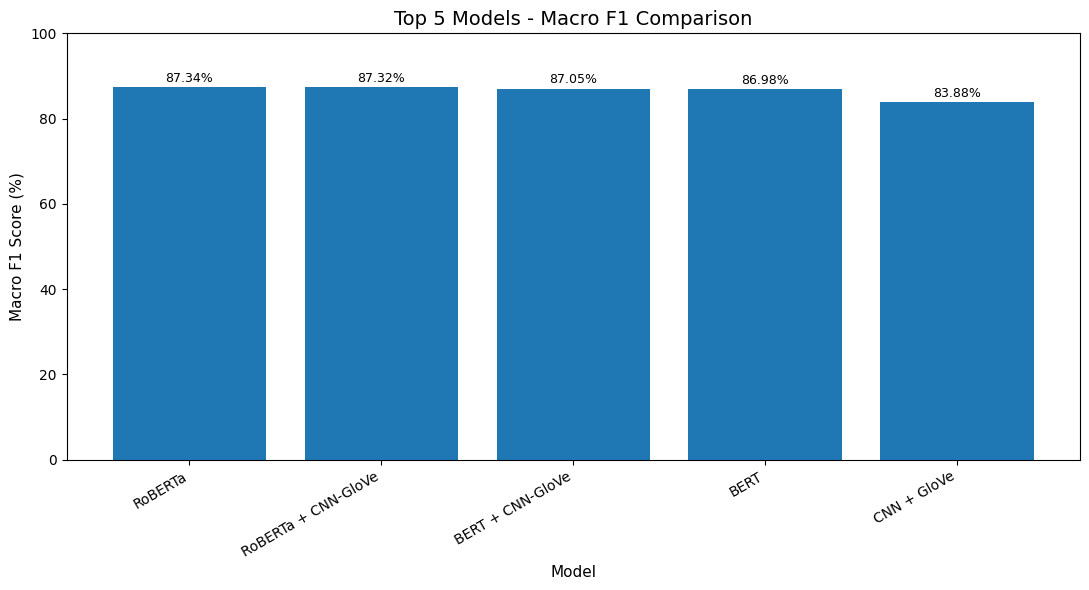

Top 5 Macro F1 chart saved: /content/drive/MyDrive/multiclass-cyberbullying-detection/results/figures/top_5_models_macro_f1.png


In [6]:

import matplotlib.pyplot as plt
import pandas as pd

# Load comparison results
comparison_df = pd.read_csv(
    METRICS_DIR / "final_model_comparison.csv"
)

# Select the five highest Macro F1 scores
top_models = (
    comparison_df
    .nlargest(5, "F1_Macro")
    .sort_values("F1_Macro", ascending=False)
    .copy()
)

# Convert scores to percentages
top_models["F1_Macro"] *= 100

# Create chart
plt.figure(figsize=(11, 6))

bars = plt.bar(
    top_models["Model"],
    top_models["F1_Macro"]
)

plt.xlabel("Model", fontsize=11)
plt.ylabel("Macro F1 Score (%)", fontsize=11)
plt.title(
    "Top 5 Models - Macro F1 Comparison",
    fontsize=14
)

plt.ylim(0, 100)
plt.xticks(rotation=30, ha="right")

# Add percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

# Save chart
chart_path = FIGURES_DIR / "top_5_models_macro_f1.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Top 5 Macro F1 chart saved:", chart_path)
